# Phase 2 · 15단원 — 시계열 기초

> "과거 실적은 미래를 예측합니다. 정상성을 먼저 확인했다면요."
> (📗 원문의 여는 문장입니다.)

- 원문: <https://aiengineeringfromscratch.com/lesson?path=phases/02-ml-fundamentals/15-time-series>
- 예상 시간: 90분 · 선수 지식: Phase 2의 1~9단원

---

## 📌 출처 표시 규칙

> 📗 **원문** — 커리큘럼에 있는 내용입니다.

> ✨ **추가** — 원문에는 없고, 제가 넣은 비유·예시·실험입니다.

> ⚠️ 표시가 붙은 곳은 원문의 주장이 측정과 달랐던 곳입니다. 그대로 적었습니다.

---

## 🎯 이 단원에서 배우는 것

> 📗 **원문** — "Learning Objectives"

1. 시계열을 **추세 · 계절성 · 잔차**로 쪼개고 **정상성**을 검사합니다.
2. **시차 특징**과 **롤링 통계**로 시계열을 보통의 지도학습 문제로 바꿉니다.
3. 미래 데이터가 훈련에 새지 않는 walk-forward 검증을 만듭니다.
4. 랜덤 분할이 왜 시계열에서 틀렸는지, 성능이 얼마나 부풀려지는지 측정합니다.

### 🔑 이 단원의 핵심 한 줄

지금까지 14단원 동안 쓴 도구가 거의 전부 **"샘플 순서는 상관없다"** 는 가정 위에 있었습니다.
시계열은 그 가정을 깹니다. 그래서 교차검증부터 다시 배웁니다.

> 📗 원문: "You reach for your standard ML toolkit: random train/test split,
> cross-validation, feature matrix in, prediction out. Every step is wrong."
>
> (표준 도구를 꺼내 듭니다. 랜덤 분할, 교차검증, 특징 행렬 넣고 예측 받기.
> 모든 단계가 틀렸습니다.)

---

## 📖 목차

| 절 | 내용 | 출처 |
| --- | --- | --- |
| 1 | 시간 데이터는 왜 다른가 (i.i.d. 가정이 깨집니다) | 📗 원문 |
| 2 | 시계열의 세 조각: 추세 · 계절성 · 잔차 | 📗 원문 |
| 3 | 정상성과 차분 (원문의 숫자 예제 재현 + ADF 검정) | 📗 원문 + ✨ 추가 |
| 4 | 자기상관 ACF와 PACF: 과거를 얼마나 기억하나 | 📗 원문 |
| 5 | 시차 특징: 시계열을 지도학습으로 바꾸는 다리 | 📗 원문 |
| 6 | ⚠️ 목표 정렬 함정: 가장 흔한 버그를 직접 만들어 봅니다 | 📗 원문 + ✨ 추가 |
| 7 | walk-forward 검증 직접 구현 + sklearn TimeSeriesSplit | 📗 원문 |
| 8 | ⚠️ 랜덤 분할은 성능을 얼마나 부풀리나 (모델에 따라 다릅니다) | 📗 연습문제 3번 |
| 9 | ⚠️ 트리가 추세를 다룬다는 말의 진위 | 📗 원문 + ✨ 측정 |
| 10 | 이겨야 하는 기준선 3개 | 📗 Ship It |
| 11 | 평가 지표 MAE · RMSE · MAPE (MAPE가 터지는 지점) | 📗 원문 |
| 12 | ⚠️ 롤링 특징과 달력 특징: 뭐가 실제로 도움이 되나 | 📗 연습문제 4번 |
| 13 | SimpleAR 직접 구현 vs sklearn | 📗 Build It |
| 14 | ARIMA 직관 (p, d, q) + statsmodels | 📗 원문 |
| 15 | 다중 스텝 예측: 재귀 vs 직접 (지평선을 늘려 봅니다) | 📗 연습문제 5번 |
| 16 | 정리 · Ship It 프롬프트 · 용어 · 퀴즈 | 📗 원문 `outputs/` · `quiz.json` + ✨ 추가 |

### 🗺️ 이 단원은 이렇게 이어집니다

목차만 보면 조각조각이지만, 실은 **하나의 질문**을 따라갑니다.
"시간이 붙은 데이터로 어떻게 정직하게 모델을 만드나?"

- **1절**에서 문제를 정의합니다. 샘플이 서로 독립이 아니고, 분포가 시간에 따라 변합니다.
- 그래서 먼저 데이터를 들여다봐야 합니다. **2절**에서 추세·계절성·잔차로 쪼갭니다.
- 쪼개 보면 "평균이 흐른다"는 게 보입니다. 이게 **3절**의 정상성 문제입니다. 해법은 차분입니다.
- 정상성을 맞췄으면 "과거 몇 개를 봐야 하나"를 정해야 합니다. **4절**의 ACF가 그걸 알려줍니다.
- ACF가 정해 준 개수만큼 과거 값을 열로 세우면 보통의 특징 행렬이 됩니다. **5절**의 시차 특징입니다.
- 여기서 사고가 납니다. 열을 한 칸 잘못 밀면 미래가 섞입니다. **6절**에서 그 버그를 일부러 만들어 봅니다.
- 미래 누출은 특징에서만 나는 게 아닙니다. **분할 자체에서도** 납니다. 그래서 **7절**의 walk-forward가 필요합니다.
- **8절**에서 "랜덤 분할을 쓰면 얼마나 부풀려지나"를 숫자로 잽니다. 여기서 모델별로 답이 갈립니다.
- 그 갈림의 원인이 **9절**입니다. 트리는 훈련 범위 밖을 예측할 수 없습니다. 추세가 있으면 무너집니다.
- 무너졌는지 알려면 비교 대상이 필요합니다. **10절**의 기준선 3개, **11절**의 지표입니다.
- 기준선을 못 넘으면 특징을 늘려 봅니다. **12절**에서 롤링·달력 특징의 실제 효과를 잽니다.
- **13절**은 지금까지 쓴 걸 손으로 만들어 보는 절입니다. AR 모델은 결국 2단원의 선형 회귀입니다.
- **14절**은 고전 모델 ARIMA가 그 AR에 무엇을 더한 것인지 봅니다.
- **15절**은 "한 걸음 뒤"가 아니라 "다섯 걸음 뒤"를 예측해야 할 때의 전략입니다.

한 문장으로 꿰면 이렇습니다.
**정상성을 맞추고(2~3절) → 과거를 특징으로 세우고(4~6절) → 시간을 지키며 검증하고(7~9절) →
기준선과 비교하고(10~12절) → 손으로 만들어 이해한 뒤(13~14절) → 멀리 예측합니다(15절).**

---

## 🧭 길잡이 — 이 단원을 왜 배우나

### 지금 어디쯤 와 있나

1단원부터 13단원까지는 **"어떤 모델이 더 좋은가"** 를 배웠습니다.
선형이냐 트리냐, 규제를 얼마나 걸 것이냐 같은 이야기였죠.

14단원부터는 질문이 바뀝니다.
**"지금까지 당연하게 쓰던 기본값이 통하지 않는 상황"** 을 하나씩 보게 됩니다.
네 단원이 한 묶음이에요.

**14단원**은 텍스트입니다. 특징이 수만 개인데 샘플은 적죠. 여기서 "정교한 모델일수록 낫다"는
감각이 깨집니다. 세기만 하는 단순한 모델이 이기거든요.

**15단원**은 시간이 붙은 데이터입니다. 샘플이 서로 독립이 아니라서, 9단원에서 배운
k-겹 교차검증을 쓸 수가 없습니다.

**16단원과 17단원**은 찾는 대상이 아주 드문 경우입니다. 레이블이 없으면 16단원(이상 탐지),
있으면 17단원(불균형 데이터)이고, 둘 다 정확도와 기본 임곗값 0.5 를 버리는 데서 출발합니다.

그래서 이 네 단원은 한마디로 **기본값을 의심하는 연습**입니다.
절 제목에 ⚠️ 가 붙은 곳이 바로 그 기본값이 깨지는 지점이에요.
시간이 없으시면 거기부터 보셔도 됩니다.

> 🧭 **지금 보시는 15단원**은 시간이 붙은 데이터입니다. 샘플이 서로 독립이 아니라서, 9단원에서 배운 k-겹 교차검증을 **쓸 수가 없습니다.** 검증하는 법부터 다시 배웁니다.


### 이 단원이 끝나면 할 수 있는 것

시간이 붙은 데이터로 모델을 만들 때 **검증을 정직하게 설계**할 수 있게 됩니다.
"백테스트는 좋은데 실전에서 안 맞는다"는 흔한 상황의 원인 두 가지를 찾아낼 수 있게 되고요.
추세가 있는 데이터에 부스팅을 쓸 때 왜 먼저 차분해야 하는지도 알게 됩니다.
그리고 "다음 분기를 예측해 주세요"라는 요청을 받았을 때,
모델 이야기를 꺼내기 전에 **먼저 되물어야 할 것**이 생깁니다.

### 실험을 따라가는 순서

**1절**은 같은 숫자를 섞어 놓고 시작합니다.
두 계열의 평균과 표준편차가 **같다**는 줄을 보세요.
값의 집합은 똑같은데 오른쪽 그림에는 예측할 게 하나도 없습니다.
정보가 값이 아니라 **순서**에 있었던 거죠. 섞는 모든 절차가 금지되는 이유가 여기서 나옵니다.

**2절**에서 계열을 추세·계절성·잔차로 쪼갭니다. 잔차의 시차-1 자기상관이
유의 경계를 넘는 걸 눈여겨보세요. 아직 덜 쪼갰다는 신호입니다.

**3절**은 "몇 번 차분해야 하나"입니다. `ADF p값` 하나만 보면 안 됩니다.
`롤링평균 폭` 과 `표준편차` 를 **같이** 보세요.
차분을 거듭할수록 표준편차가 커지는 게 보일 겁니다.
p값만 쫓으면 필요 이상으로 차분해서 신호까지 깎습니다.

**4절**은 시차를 몇 개 만들지 정하려고 ACF 를 봅니다.
절댓값 상위 시차에 7과 14가 뜨죠. 주기를 찾아 줍니다.
다만 **개수는 여기서 확정하지 마세요.** 13절에서 다시 정합니다.

**5절**에서 과거 값을 열로 세우면 보통의 특징 행렬이 됩니다. 여기까지가 준비입니다.

**6절**부터 사고가 납니다. 일부러 버그를 만들어 보는데,
`테스트 R² 1.000000` 과 첫 번째 계수 0.999 를 보세요.
**에러가 안 납니다.** 코드는 잘 돌고 그래프도 예쁩니다. 그래서 가장 위험한 버그입니다.

**7절**에서 올바른 검증을 만듭니다.
훈련 끝이 테스트 시작보다 항상 작거나 같다는 열만 확인하면 됩니다.

**8절**은 "그럼 틀린 분할을 쓰면 얼마나 부풀려지나"입니다. `부풀림` 열을 보세요.
Ridge 는 +0.07 인데 랜덤 포레스트는 +0.56 입니다. **모델에 따라 다르다**는 게 핵심이에요.
랜덤 분할이 외삽 못 하는 모델의 약점을 가려 준다는 뜻이거든요.

**9절**이 그 이유를 밝힙니다. `예측 최대` 열에서 부스팅이 **81.87** 에서 멈추는데
테스트 실제값은 **92.99** 까지 갑니다.
트리는 잎에 담긴 훈련 샘플의 평균을 내놓으니 훈련 최댓값을 구조적으로 못 넘습니다.

**10절**은 비교 대상을 세웁니다. 계절 나이브의 MAE **2.360** 을 기억해 두세요.
이걸 못 넘는 모델이 나오면 멈추고 원인을 찾아야 합니다.

**11절**은 지표 셋을 정리하고, MAPE 가 실제값 0에서 `inf` 가 되는 걸 보여 줍니다.

**12절**에서는 롤링평균7 을 lag1~7 로 맞춘 `R² = 1.0000000000` 한 줄이 전부입니다.
롤링 평균이 시차들의 **정확한 선형 결합**이라는 뜻이고, 그러면 선형 모델에게 정보량이 0 입니다.
반면 달력 특징은 과거 값으로 만들 수 없으니 진짜 새 정보죠.

**13절**에서 시차 개수를 확정합니다.
`상태` 열이 과소적합 → **최고(50)** → 과적합 으로 바뀌는 걸 따라가세요.
4절의 ACF 가 말한 7·14보다 훨씬 많습니다. ACF 는 출발점이고 확정은 검증 곡선이 합니다.

**14절**은 ARIMA 가 13절의 AR 모델에 무엇을 더한 것인지 봅니다.
그리고 120스텝을 한 번에 예보하면 **모든 모델이 계절 나이브에 진다**는 것도 같이요.

**15절**은 멀리 예측할 때의 전략입니다.
지평선별 `차이` 열의 **부호가 바뀌는 지점(10)** 을 보세요.
1~5스텝은 재귀, 그보다 길면 직접입니다.

### 한 문장으로 꿰면

훈련 구간은 **항상 테스트 구간보다 앞**이어야 하고,
목표를 한 칸만 잘못 밀어도 오류 없이 조용히 틀리며,
추세가 있는데 트리 계열을 쓸 거면 반드시 차분하세요.

---

## ⚙️ 0. 준비

폰트를 먼저 잡습니다. `DejaVu Sans` 를 앞에 두는 게 중요합니다.
안 그러면 그래프의 음수 기호(−)가 두부(□)로 나옵니다.

In [1]:
import warnings
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.font_manager import findfont, FontProperties

warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True)

# 한글 폰트를 찾되, DejaVu Sans 를 먼저 둡니다.
# 순서가 중요합니다. DejaVu 가 앞이어야 유니코드 마이너스(−)가 제대로 그려지고,
# DejaVu 에 없는 한글은 자동으로 뒤쪽 폰트로 넘어갑니다.
후보들 = ["AppleGothic", "Apple SD Gothic Neo", "Malgun Gothic", "NanumGothic"]
찾은것 = None
for 후보 in 후보들:
    try:
        if 후보.lower().replace(" ", "") in findfont(FontProperties(family=후보)).lower().replace(" ", ""):
            찾은것 = 후보
            break
    except Exception:
        pass
matplotlib.rcParams["font.family"] = ["DejaVu Sans"] + ([찾은것] if 찾은것 else [])
matplotlib.rcParams["axes.unicode_minus"] = False
matplotlib.rcParams["figure.dpi"] = 110

print("준비 끝!  한글 폰트:", 찾은것 or "(없음 — 한글이 □ 로 보일 수 있습니다)")

준비 끝!  한글 폰트: AppleGothic


---

## 1. 시간 데이터는 왜 다른가

> 📗 **원문** — "The Problem" + "What Makes Time Series Different"

### 🧸 먼저 비유

반에서 30명을 뽑아 키를 재는 상황을 생각해 보세요.
누구를 먼저 재든 결과는 같습니다. 순서가 아무 의미가 없습니다.
이게 지금까지 14단원 동안 쓴 가정입니다. 전문 용어로 **i.i.d.** 라고 합니다.

이번엔 한 사람의 키를 1학년부터 6학년까지 매년 잰다고 해 보세요.
이제 순서가 **전부**입니다. 섞으면 성장이라는 정보가 사라집니다.
그리고 5학년 키는 4학년 키와 거의 같습니다. 서로 독립이 아닙니다.

### 📐 깨지는 가정이 정확히 두 개입니다

> 📗 원문: "Time series violates both."

| 가정 | 뜻 | 시계열에서 | 결과 |
| --- | --- | --- | --- |
| **독립** (independent) | 샘플끼리 영향 없음 | 오늘 주가는 어제 주가에 달려 있습니다 | 랜덤 분할이 미래를 흘립니다 |
| **동일 분포** (identically distributed) | 분포가 안 바뀜 | 12월 매출과 3월 매출은 다릅니다 | 과거로 학습한 평균이 틀립니다 |

이 두 가지가 깨지면 바뀌는 게 세 개입니다. 특징 만드는 법, 검증하는 법, 알고리즘 선택.
이 단원이 그 세 개를 차례로 다룹니다.

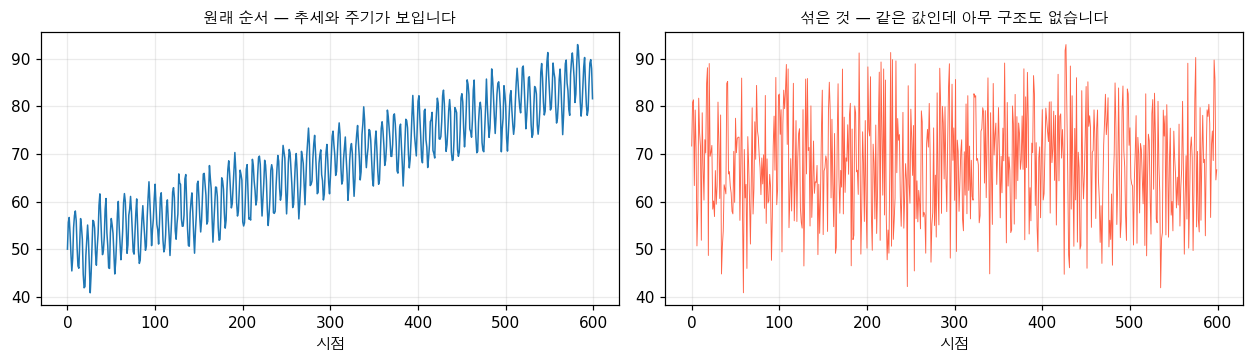

두 계열의 평균   67.8271 / 67.8271   (같습니다)
두 계열의 표준편차 11.3154 / 11.3154   (같습니다)

=> 값의 집합은 완전히 같습니다. 히스토그램을 그리면 똑같이 나옵니다.
   그런데 오른쪽에서는 예측할 게 하나도 없습니다.
   정보가 '값'에 있는 게 아니라 '순서'에 있었기 때문입니다.

   이게 시계열의 출발점입니다. 그래서 섞는 모든 절차(랜덤 분할, k-겹 교차검증)가
   시계열에서는 쓸 수 없습니다. 7절에서 대체물을 만듭니다.


In [2]:
# ✨ 추가 — '순서가 전부'라는 말을 그림으로 확인합니다
난수 = np.random.default_rng(7)
n = 600
t = np.arange(n)

추세 = 0.06 * t                                 # 하루 0.06 씩 오릅니다
계절 = 6.0 * np.sin(2*np.pi*t/7) + 2.5*np.sin(2*np.pi*t/30)   # 주간 + 월간 주기
잡음 = 난수.normal(0, 1.2, n)
계열 = 50 + 추세 + 계절 + 잡음                   # 이 단원 내내 쓸 계열입니다

섞은것 = 계열.copy()
난수.shuffle(섞은것)

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.4))
ax[0].plot(t, 계열, lw=1.0)
ax[0].set_title("원래 순서 — 추세와 주기가 보입니다", fontsize=10)
ax[1].plot(t, 섞은것, lw=0.6, color="tomato")
ax[1].set_title("섞은 것 — 같은 값인데 아무 구조도 없습니다", fontsize=10)
for a_ in ax:
    a_.set_xlabel("시점"); a_.grid(alpha=0.25)
plt.tight_layout(); plt.show()

print(f"두 계열의 평균   {계열.mean():.4f} / {섞은것.mean():.4f}   (같습니다)")
print(f"두 계열의 표준편차 {계열.std():.4f} / {섞은것.std():.4f}   (같습니다)")
print("\n=> 값의 집합은 완전히 같습니다. 히스토그램을 그리면 똑같이 나옵니다.")
print("   그런데 오른쪽에서는 예측할 게 하나도 없습니다.")
print("   정보가 '값'에 있는 게 아니라 '순서'에 있었기 때문입니다.")
print("\n   이게 시계열의 출발점입니다. 그래서 섞는 모든 절차(랜덤 분할, k-겹 교차검증)가")
print("   시계열에서는 쓸 수 없습니다. 7절에서 대체물을 만듭니다.")

---

## 2. 시계열의 세 조각: 추세 · 계절성 · 잔차

> 🔗 **앞 절과 이어서** — 1절에서 "정보는 순서에 있다"는 걸 봤습니다.
> 그러면 그 순서에 어떤 종류의 정보가 들어 있는지 분류해야 합니다. 세 가지입니다.

> 📗 **원문** — "Components of a Time Series"

| 조각 | 뜻 | 예 |
| --- | --- | --- |
| **추세** (trend) | 길게 보면 올라가거나 내려가는 방향 | 매년 10% 성장하는 매출 |
| **계절성** (seasonality) | 일정한 간격으로 반복되는 무늬 | 12월에 뛰는 소매 매출 |
| **잔차** (residual) | 추세와 계절성을 빼고 남은 것 | 설명 안 되는 나머지 |

### 🧸 쉬운 말로

계단을 올라가면서 좌우로 흔들리며 걷는 사람을 생각해 보세요.
**계단**이 추세고, **좌우 흔들림**이 계절성이고, **발을 삐끗하는 것**이 잔차입니다.

### 🔑 잔차가 왜 중요한가

> 📗 원문: "If the residual looks like white noise, the decomposition captured the signal."

잔차가 **백색 잡음**처럼 보이면 쪼개기가 잘 된 겁니다.
잔차에 아직 무늬가 남아 있으면 **덜 쪼갠 것**입니다. 더 찾을 게 있다는 신호죠.

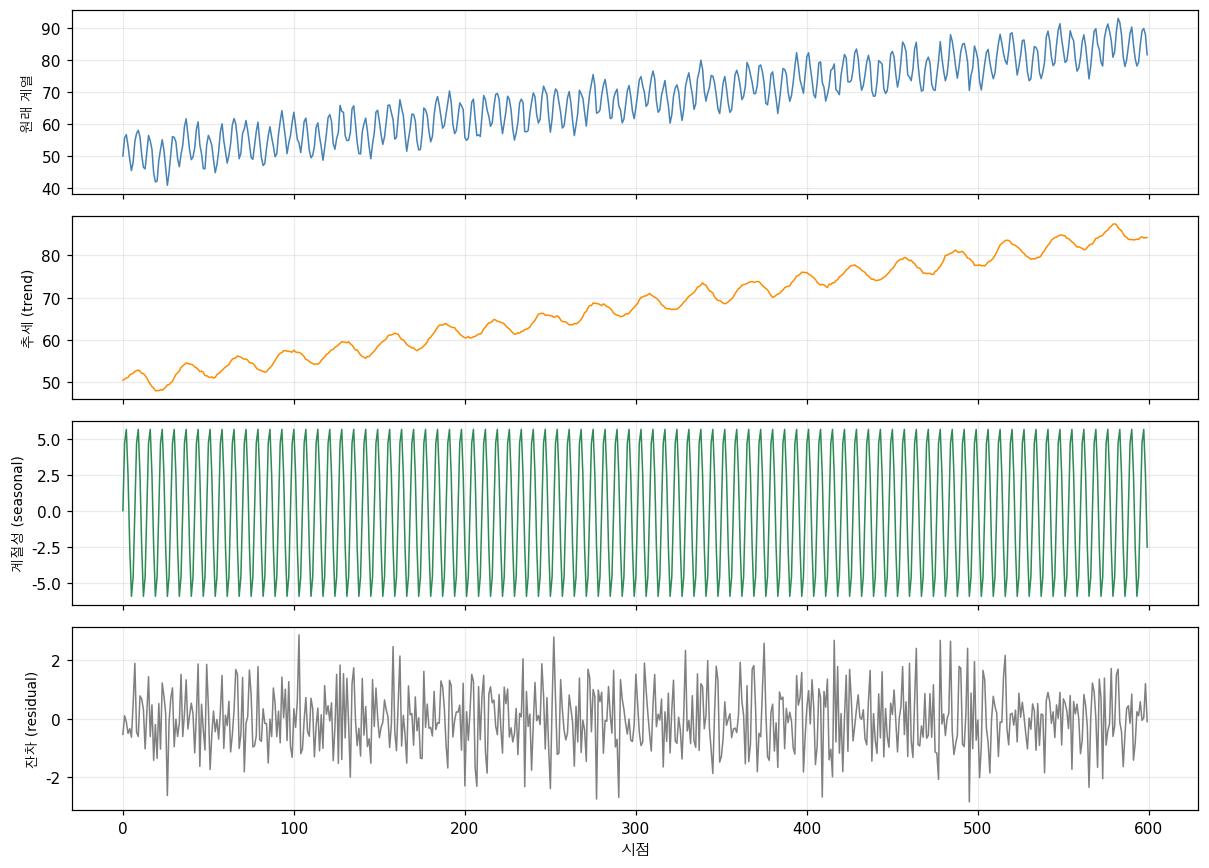

조각                      분산       전체 대비
----------------------------------------
추세                108.8999      85.1%
계절성                17.6690      13.8%
잔차                  1.0784       0.8%
합계(원계열)          128.0392     100.0%

잔차의 평균 = 0.0012  (0 에 가까우면 좋습니다)
잔차의 표준편차 = 1.0384  (내가 넣은 잡음은 1.2 였습니다)
잔차의 시차-1 자기상관 = -0.1526  (유의 경계 ±0.0800)

=> 📗 원문은 '잔차가 백색 잡음처럼 보이면 신호를 다 잡은 것' 이라고 합니다.
   여기서는 절반만 그렇습니다. 두 가지를 보세요.

   · 잔차 표준편차 1.0384 는 내가 넣은 잡음 1.2 보다 13% 작습니다.
     쪼개기가 잡음의 일부까지 계절성으로 흡수했다는 뜻입니다
   · 시차-1 자기상관이 -0.1526 로 유의 경계를 넘습니다. 백색 잡음이면 0 이어야 합니다

   => 남은 무늬가 있습니다. 30일 주기를 period=7 로는 못 잡았기 때문입니다.
      즉 '잔차를 보면 덜 쪼갠 게 보인다'는 원문의 진단법 자체는 제대로 작동합니다.

   ⚠️ 쪼개기는 '내가 알려준 주기'만 찾아냅니다. period=7 이라고 했으니 7일 주기만 봤죠.
      그래서 30일 주기는 추세와 잔차로 흩어집니다 (위 표에서 추세가 85% 를 먹은 이유).
      주기를 모르면 4절의 ACF로 먼저 찾아야 합니다.


In [3]:
from statsmodels.tsa.seasonal import seasonal_decompose

# 주기가 7(주간)이라고 알려 주고 쪼갭니다
분해 = seasonal_decompose(계열, period=7, model="additive", extrapolate_trend="freq")

fig, ax = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
for a_, (라벨, 값, 색) in zip(ax, [
        ("원래 계열", 계열, "steelblue"),
        ("추세 (trend)", 분해.trend, "darkorange"),
        ("계절성 (seasonal)", 분해.seasonal, "seagreen"),
        ("잔차 (residual)", 분해.resid, "gray")]):
    a_.plot(t, 값, lw=1.0, color=색)
    a_.set_ylabel(라벨, fontsize=9); a_.grid(alpha=0.25)
ax[-1].set_xlabel("시점")
plt.tight_layout(); plt.show()

# 각 조각이 전체 변동의 몇 퍼센트를 설명하나
총분산 = 계열.var()
print(f"{'조각':<14}{'분산':>12}{'전체 대비':>12}")
print("-" * 40)
for 라벨, 값 in [("추세", 분해.trend), ("계절성", 분해.seasonal), ("잔차", 분해.resid)]:
    v = np.nanvar(값)
    print(f"{라벨:<14}{v:>12.4f}{v/총분산:>11.1%}")
print(f"{'합계(원계열)':<13}{총분산:>12.4f}{1.0:>11.1%}")

잔차만 = 분해.resid[~np.isnan(분해.resid)]
print(f"\n잔차의 평균 = {잔차만.mean():.4f}  (0 에 가까우면 좋습니다)")
print(f"잔차의 표준편차 = {잔차만.std():.4f}  (내가 넣은 잡음은 1.2 였습니다)")

# 잔차에 아직 무늬가 남았나: 시차 1 자기상관으로 봅니다
r1 = np.corrcoef(잔차만[:-1], 잔차만[1:])[0, 1]
경계 = 1.96 / np.sqrt(len(잔차만))
print(f"잔차의 시차-1 자기상관 = {r1:.4f}  (유의 경계 ±{경계:.4f})")
print(f"\n=> 📗 원문은 '잔차가 백색 잡음처럼 보이면 신호를 다 잡은 것' 이라고 합니다.")
print(f"   여기서는 절반만 그렇습니다. 두 가지를 보세요.")
print(f"\n   · 잔차 표준편차 {잔차만.std():.4f} 는 내가 넣은 잡음 1.2 보다 "
      f"{(1-잔차만.std()/1.2):.0%} 작습니다.")
print(f"     쪼개기가 잡음의 일부까지 계절성으로 흡수했다는 뜻입니다")
print(f"   · 시차-1 자기상관이 {r1:.4f} 로 유의 경계를 넘습니다. "
      f"백색 잡음이면 0 이어야 합니다")
print(f"\n   => 남은 무늬가 있습니다. 30일 주기를 period=7 로는 못 잡았기 때문입니다.")
print(f"      즉 '잔차를 보면 덜 쪼갠 게 보인다'는 원문의 진단법 자체는 제대로 작동합니다.")
print("\n   ⚠️ 쪼개기는 '내가 알려준 주기'만 찾아냅니다. period=7 이라고 했으니 7일 주기만 봤죠.")
print("      그래서 30일 주기는 추세와 잔차로 흩어집니다 (위 표에서 추세가 85% 를 먹은 이유).")
print("      주기를 모르면 4절의 ACF로 먼저 찾아야 합니다.")

---

## 3. 정상성과 차분

> 🔗 **앞 절과 이어서** — 2절에서 추세를 분리해 냈습니다.
> 그런데 추세가 남아 있으면 모델이 곤란해집니다. 왜 곤란한지, 어떻게 없애는지가 이 절입니다.

> 📗 **원문** — "Stationarity"

### 📐 정상성이란

통계적 성질(평균, 분산, 자기상관)이 시간에 따라 변하지 않는 것입니다.

### 🧸 왜 문제인가

> 📗 원문: "A model trained on data from January has learned a different mean than
> what February will show. It will be systematically wrong."

1월 데이터로 "평균 매출은 100" 이라고 배운 모델이 있습니다.
매출이 매달 오르고 있다면, 2월의 진짜 평균은 110입니다.
이 모델은 **매번 10씩 모자라게** 예측합니다. 틀리는 방향이 한쪽으로 쏠립니다.
운이 나빠서 틀리는 게 아니라 **구조적으로** 틀립니다.

### 🔨 해법: 차분

값 자체가 아니라 **값의 변화**를 모델링합니다.

$$\text{diff}[t] = \text{value}[t] - \text{value}[t-1]$$

매출이 100 → 110 → 120 이면, 차분은 10 → 10 입니다. 평균이 안 흐릅니다.

> 📗 원문의 숫자 예제를 그대로 확인해 봅니다.
> 원본 `[100, 102, 106, 112, 120]` → 1차 차분 `[2, 4, 6, 8]` → 2차 차분 `[2, 2, 2]`

📗 원문 예제 재현
   원본     [100 102 106 112 120]
   1차 차분 [2 4 6 8]          <- 아직 올라가고 있습니다
   2차 차분 [2 2 2]             <- 상수입니다. 정상입니다

   원본은 2차 함수 모양이었습니다. 한 번 차분하면 1차(직선), 두 번이면 상수가 됩니다.
   📗 원문: 'In practice, you rarely need more than two rounds.'


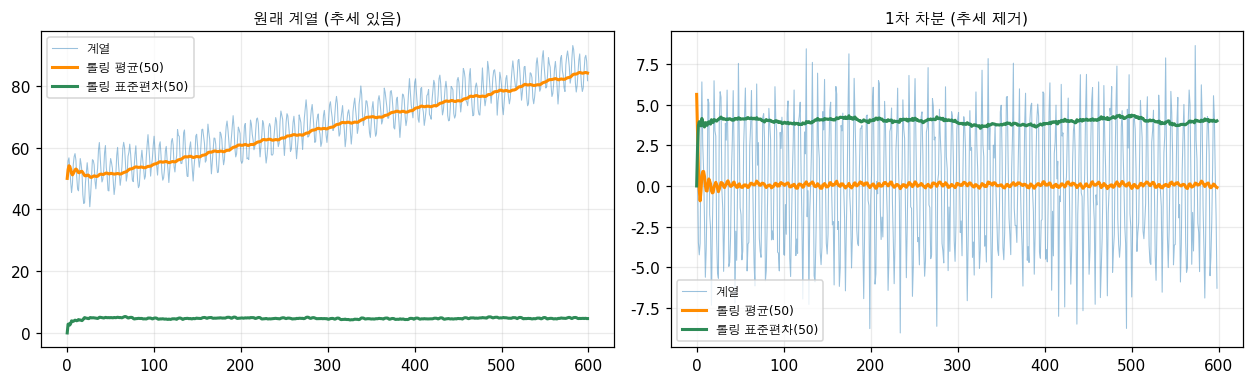

원래 계열      롤링 평균이    51.38 ~    84.28 사이를 움직입니다 (폭 32.91)
1차 차분      롤링 평균이    -0.16 ~     0.30 사이를 움직입니다 (폭 0.47)

=> 왼쪽 그림의 주황색 선이 계속 올라갑니다. 평균이 흐르고 있습니다.
   오른쪽은 평평합니다. 차분 한 번으로 정상이 됐습니다.


In [4]:
# 📗 원문의 숫자 예제를 그대로 재현합니다
원문예제 = np.array([100, 102, 106, 112, 120])
print("📗 원문 예제 재현")
print(f"   원본     {원문예제}")
print(f"   1차 차분 {np.diff(원문예제)}          <- 아직 올라가고 있습니다")
print(f"   2차 차분 {np.diff(원문예제, 2)}             <- 상수입니다. 정상입니다")
print("\n   원본은 2차 함수 모양이었습니다. 한 번 차분하면 1차(직선), 두 번이면 상수가 됩니다.")
print("   📗 원문: 'In practice, you rarely need more than two rounds.'")

# ✨ 추가 — 롤링 통계로 눈으로 확인합니다 (원문의 check_stationarity 방식)
def 롤링통계(s, 창=50):
    평균 = np.array([s[max(0, i-창):i].mean() for i in range(1, len(s)+1)])
    표준 = np.array([s[max(0, i-창):i].std() if i > 1 else 0.0 for i in range(1, len(s)+1)])
    return 평균, 표준

차분계열 = np.diff(계열)
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.6))
for a_, (라벨, s) in zip(ax, [("원래 계열 (추세 있음)", 계열), ("1차 차분 (추세 제거)", 차분계열)]):
    평균, 표준 = 롤링통계(s)
    a_.plot(s, lw=0.7, alpha=0.45, label="계열")
    a_.plot(평균, lw=2.0, color="darkorange", label="롤링 평균(50)")
    a_.plot(표준, lw=2.0, color="seagreen", label="롤링 표준편차(50)")
    a_.set_title(라벨, fontsize=10); a_.grid(alpha=0.25); a_.legend(fontsize=8)
plt.tight_layout(); plt.show()

for 라벨, s in [("원래 계열", 계열), ("1차 차분", 차분계열)]:
    평균, 표준 = 롤링통계(s)
    유효 = 평균[50:]
    print(f"{라벨:<10} 롤링 평균이 {유효.min():>8.2f} ~ {유효.max():>8.2f} 사이를 "
          f"움직입니다 (폭 {유효.max()-유효.min():.2f})")
print("\n=> 왼쪽 그림의 주황색 선이 계속 올라갑니다. 평균이 흐르고 있습니다.")
print("   오른쪽은 평평합니다. 차분 한 번으로 정상이 됐습니다.")

### ✨ 추가 — 눈으로 보는 것 말고 검정으로

> 📗 원문은 ADF 검정을 설명만 하고 구현하지 않습니다.
> "We do not implement ADF from scratch (it requires asymptotic distribution tables)."
> `statsmodels` 에 있으니 가져다 쓰겠습니다. 쓰는 법과 읽는 법만 알면 됩니다.

ADF(Augmented Dickey-Fuller) 검정의 귀무가설은 "이 계열은 **비정상**이다" 입니다.
그래서 **p값이 0.05보다 작으면** 귀무가설을 기각하고 "정상이다" 라고 말합니다.

> 귀무가설이 뒤집혀 있어서 헷갈립니다. 이렇게 외우세요.
> p값이 작으면 정상(좋은 것), p값이 크면 비정상(차분 필요).

아래에서 📗 원문 **연습문제 1번**("2차 추세는 몇 번 차분해야 하나?")을 풉니다.

In [5]:
from statsmodels.tsa.stattools import adfuller

# 📗 연습문제 1번 — 선형 추세와 2차 추세를 각각 차분해 가며 ADF p값을 봅니다
전용난수 = np.random.default_rng(1234)          # 이 실험만의 고정 난수
선형추세계열 = 50 + 0.06*t + 전용난수.normal(0, 1.2, n)
이차추세계열 = 50 + 0.0004*t**2 + 전용난수.normal(0, 1.2, n)

print(f"{'계열':<12}{'차분':>5}{'ADF p값':>11}{'판정':>9}"
      f"{'롤링평균 폭':>13}{'앞/뒤 평균차':>14}{'표준편차':>10}")
print("-" * 78)
for 라벨, s0 in [("선형 추세", 선형추세계열), ("2차 추세", 이차추세계열)]:
    for d in range(3):
        s = s0 if d == 0 else np.diff(s0, d)
        p = adfuller(s, autolag="AIC")[1]
        평균, _ = 롤링통계(s)
        폭 = 평균[50:].max() - 평균[50:].min()
        앞, 뒤 = s[:len(s)//2], s[len(s)//2:]
        print(f"{라벨 if d == 0 else '':<12}{d:>5}{p:>11.4f}"
              f"{'정상' if p < 0.05 else '비정상':>9}{폭:>13.3f}"
              f"{abs(앞.mean()-뒤.mean()):>14.3f}{s.std():>10.3f}")
    print()

print("=> 선형 추세는 차분 한 번에 깔끔하게 정상이 됩니다 (p가 0.0000 으로 떨어짐).")
print("\n   ⚠️ 2차 추세는 답이 애매합니다. 📗 원문은 '2차 추세면 두 번' 이라고 암시하는데,")
print("      측정 결과 1차 차분에서 이미 롤링 평균이 거의 평평합니다.")
print("      그런데 ADF p값은 아직 0.05를 못 넘습니다. 검정과 눈이 다른 말을 합니다.")
print("\n   왜 그런가요? 1차 차분한 2차 추세는 '약한 직선 추세'가 남습니다.")
print("   그 기울기가 잡음보다 훨씬 작아서 눈에는 안 보이지만, 검정은 잡아냅니다.")
print("   📗 원문의 숫자 예제처럼 '완전히 상수'가 되려면 두 번이 맞습니다.")
print("\n   💡 실무 결론: p값 하나로 결정하지 마세요. 롤링 평균 그림을 같이 보세요.")
print("      그리고 차분을 한 번 더 하면 분산이 커집니다 (위 표 '표준편차' 열을 보세요).")
print("      필요 이상으로 차분하면 신호까지 깎아 먹습니다. 이걸 과차분이라고 합니다.")

계열             차분     ADF p값       판정       롤링평균 폭       앞/뒤 평균차      표준편차
------------------------------------------------------------------------------
선형 추세           0     0.9292      비정상       33.022        17.971    10.443
                1     0.0000       정상        0.190         0.005     1.734
                2     0.0000       정상        0.256         0.013     3.014

2차 추세           0     1.0000      비정상      132.069        72.031    42.933
                1     0.1813      비정상        0.596         0.235     1.712
                2     0.0000       정상        0.411         0.004     2.967

=> 선형 추세는 차분 한 번에 깔끔하게 정상이 됩니다 (p가 0.0000 으로 떨어짐).

   ⚠️ 2차 추세는 답이 애매합니다. 📗 원문은 '2차 추세면 두 번' 이라고 암시하는데,
      측정 결과 1차 차분에서 이미 롤링 평균이 거의 평평합니다.
      그런데 ADF p값은 아직 0.05를 못 넘습니다. 검정과 눈이 다른 말을 합니다.

   왜 그런가요? 1차 차분한 2차 추세는 '약한 직선 추세'가 남습니다.
   그 기울기가 잡음보다 훨씬 작아서 눈에는 안 보이지만, 검정은 잡아냅니다.
   📗 원문의 숫자 예제처럼 '완전히 상수'가 되려면 두 번이 맞습니다.

   💡 실무 결론: p값 하나로 결정하지 마세요. 롤링 평균 그림을 같이 보세요.
      그리고 차분을 한 번

---

## 4. 자기상관 ACF와 PACF

> 🔗 **앞 절과 이어서** — 3절에서 정상성을 맞췄습니다.
> 이제 "과거 몇 개를 봐야 하나"를 정해야 합니다. 그걸 알려주는 도구가 ACF입니다.

> 📗 **원문** — "Autocorrelation"

### 📐 ACF: 자기 자신과의 상관

**자기상관**은 시점 $t$의 값과 시점 $t-k$의 값이 얼마나 같이 움직이는지입니다.
$k$를 바꿔 가며 그걸 다 그린 게 **ACF(자기상관 함수)** 입니다.

### 🧸 쉬운 말로

"오늘 기온은 며칠 전 기온까지 닮아 있나?"를 재는 겁니다.
어제와는 많이 닮았겠죠. 100일 전과는 안 닮았을 겁니다.
**어디서부터 안 닮아지는지**가 ACF가 알려주는 것입니다.

### 🔑 ACF로 알 수 있는 세 가지

> 📗 원문: "ACF tells you..."

| 알 수 있는 것 | 읽는 법 |
| --- | --- |
| 계열이 과거를 얼마나 기억하나 | ACF가 시차 5에서 0이 되면, 5보다 먼 과거는 무관합니다 |
| 계절성이 있나 | 월별 데이터에서 시차 12에 뾰족하게 솟으면 연간 계절성입니다 |
| 시차 특징을 몇 개 만들까 | ACF가 무시할 만해지는 지점까지 씁니다 |

### 📐 PACF: 간접 상관을 걷어낸 것

> 📗 원문: "If today correlates with 3 days ago only because both correlate with yesterday,
> PACF at lag 3 will be zero while ACF at lag 3 will not."

ACF에는 **간접 경로**가 섞여 있습니다.
오늘이 3일 전과 상관있어 보이는 게 사실은 "오늘↔어제↔그제↔3일전" 사슬 때문일 수 있습니다.
PACF는 그 사슬을 걷어내고 **직접 연결만** 남깁니다.

> 친구 관계로 비유하면, ACF는 "친구의 친구까지 포함한 친밀도"고
> PACF는 "직접 아는 사이인지"입니다.

직접 만든 ACF를 statsmodels 와 맞춰 봅니다
   vs statsmodels 기본값          최대 차이 2.27e-02
   vs statsmodels adjusted=True   최대 차이 3.33e-16

=> ⚠️ 기본값과는 안 맞고, adjusted=True 와 정확히 맞습니다.
   📗 원문 구현이 틀린 건 아니고 다른 추정량입니다. 차이는 나누는 수입니다.

   시차       원문 구현       sm 기본        비율    N/(N-k)
----------------------------------------------------
    1    0.451642    0.450888  1.001672   1.001672
    5   -0.188171   -0.186600  1.008418   1.008418
   10   -0.761239   -0.748531  1.016978   1.016978
   20    0.511602    0.494520  1.034542   1.034542

   비율이 정확히 N/(N-k) 입니다. 시차 k에서는 곱할 수 있는 쌍이 N-k 개뿐인데,
   원문은 그 N-k 로 나누고(np.mean), statsmodels 기본값은 N 으로 나눕니다.
   · N 으로 나누기(기본값): 추정값이 0 쪽으로 쏠리지만 분산이 작습니다
   · N-k 로 나누기(원문): 평균적으로 정확하지만 큰 시차에서 불안정합니다
   시차 20에서 차이가 0.0171 입니다. 시차가 커질수록 벌어집니다.
   💡 10단원의 편향-분산이 '통계량 추정'에서도 똑같이 나오는 사례입니다.



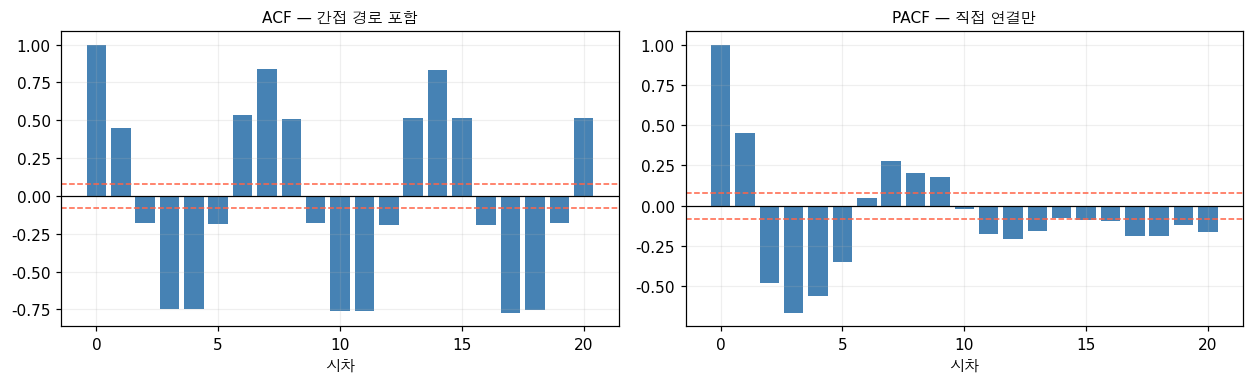

빨간 점선이 유의 경계(±0.080)입니다. 밖으로 나간 막대만 의미가 있습니다.

   시차       ACF     유의?       PACF     유의?
--------------------------------------------
    1     0.452       O      0.451       O
    2    -0.181       O     -0.482       O
    3    -0.749       O     -0.665       O
    4    -0.748       O     -0.562       O
    5    -0.188       O     -0.350       O
    6     0.534       O      0.050       -
    7     0.842       O      0.277       O
    8     0.505       O      0.201       O
    9    -0.176       O      0.177       O
   10    -0.761       O     -0.021       -
   11    -0.761       O     -0.174       O
   12    -0.192       O     -0.208       O
   13     0.517       O     -0.160       O
   14     0.833       O     -0.078       -

=> ACF가 유의한 시차: 20개 / 20개
   ⚠️ 전부입니다. 주기가 뚜렷한 계열에서는 흔한 일입니다.
      ±0.080 경계는 '백색 잡음 대비' 기준이라 주기가 있으면 다 넘습니다.
      그래서 '유의한가'보다 '어디가 가장 큰가' 를 봐야 합니다.

   ACF 절댓값 상위 5개 시차: 7(+0.84), 14(+0.83), 17(-0.77), 11(-0.76), 10(-0.76)
   시차 7과 14가 양수로 크게 나옵니다. 내가 넣은 주간 

In [6]:
# 📗 원문의 autocorrelation 구현을 그대로 옮깁니다
def 자기상관(계열값, 최대시차=20):
    N = len(계열값)
    평균 = 계열값.mean()
    분산 = 계열값.var()
    결과 = np.zeros(최대시차 + 1)
    for k in range(최대시차 + 1):
        공분산 = np.mean((계열값[:N-k] - 평균) * (계열값[k:] - 평균))
        결과[k] = 공분산 / 분산 if 분산 > 0 else 0.0
    return 결과

from statsmodels.tsa.stattools import acf as sm_acf, pacf as sm_pacf

내ACF = 자기상관(차분계열, 20)
sm기본 = sm_acf(차분계열, nlags=20, fft=False)                  # 기본값 adjusted=False
sm조정 = sm_acf(차분계열, nlags=20, fft=False, adjusted=True)   # 1/(N-k) 로 나눔
내PACF = sm_pacf(차분계열, nlags=20, method="ywm")

N차 = len(차분계열)
print("직접 만든 ACF를 statsmodels 와 맞춰 봅니다")
print(f"   vs statsmodels 기본값          최대 차이 {np.abs(내ACF-sm기본).max():.2e}")
print(f"   vs statsmodels adjusted=True   최대 차이 {np.abs(내ACF-sm조정).max():.2e}")
print(f"\n=> ⚠️ 기본값과는 안 맞고, adjusted=True 와 정확히 맞습니다.")
print(f"   📗 원문 구현이 틀린 건 아니고 다른 추정량입니다. 차이는 나누는 수입니다.")
print(f"\n{'시차':>5}{'원문 구현':>12}{'sm 기본':>12}{'비율':>10}{'N/(N-k)':>11}")
print("-" * 52)
for k in (1, 5, 10, 20):
    print(f"{k:>5}{내ACF[k]:>12.6f}{sm기본[k]:>12.6f}"
          f"{내ACF[k]/sm기본[k]:>10.6f}{N차/(N차-k):>11.6f}")
print(f"\n   비율이 정확히 N/(N-k) 입니다. 시차 k에서는 곱할 수 있는 쌍이 N-k 개뿐인데,")
print(f"   원문은 그 N-k 로 나누고(np.mean), statsmodels 기본값은 N 으로 나눕니다.")
print(f"   · N 으로 나누기(기본값): 추정값이 0 쪽으로 쏠리지만 분산이 작습니다")
print(f"   · N-k 로 나누기(원문): 평균적으로 정확하지만 큰 시차에서 불안정합니다")
print(f"   시차 20에서 차이가 {abs(내ACF[20]-sm기본[20]):.4f} 입니다. "
      f"시차가 커질수록 벌어집니다.")
print(f"   💡 10단원의 편향-분산이 '통계량 추정'에서도 똑같이 나오는 사례입니다.\n")

표준오차 = 1.96 / np.sqrt(len(차분계열))        # 95% 유의 경계 근사
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.6))
for a_, (라벨, 값) in zip(ax, [("ACF — 간접 경로 포함", 내ACF), ("PACF — 직접 연결만", 내PACF)]):
    a_.bar(range(len(값)), 값, color="steelblue")
    a_.axhline(0, color="black", lw=0.8)
    a_.axhline(표준오차, color="tomato", ls="--", lw=1.0)
    a_.axhline(-표준오차, color="tomato", ls="--", lw=1.0)
    a_.set_title(라벨, fontsize=10); a_.set_xlabel("시차"); a_.grid(alpha=0.2)
plt.tight_layout(); plt.show()

print(f"빨간 점선이 유의 경계(±{표준오차:.3f})입니다. 밖으로 나간 막대만 의미가 있습니다.\n")
print(f"{'시차':>5}{'ACF':>10}{'유의?':>8}{'PACF':>11}{'유의?':>8}")
print("-" * 44)
for k in range(1, 15):
    print(f"{k:>5}{내ACF[k]:>10.3f}{'O' if abs(내ACF[k]) > 표준오차 else '-':>8}"
          f"{내PACF[k]:>11.3f}{'O' if abs(내PACF[k]) > 표준오차 else '-':>8}")

유의시차 = [k for k in range(1, 21) if abs(내ACF[k]) > 표준오차]
상위 = sorted(range(1, 21), key=lambda k: -abs(내ACF[k]))[:5]
print(f"\n=> ACF가 유의한 시차: {len(유의시차)}개 / 20개")
print(f"   ⚠️ {'전부입니다' if len(유의시차) == 20 else '거의 전부입니다'}. "
      f"주기가 뚜렷한 계열에서는 흔한 일입니다.")
print(f"      ±{표준오차:.3f} 경계는 '백색 잡음 대비' 기준이라 주기가 있으면 다 넘습니다.")
print(f"      그래서 '유의한가'보다 '어디가 가장 큰가' 를 봐야 합니다.")
print(f"\n   ACF 절댓값 상위 5개 시차: "
      f"{', '.join(f'{k}({내ACF[k]:+.2f})' for k in 상위)}")
print(f"   시차 7과 14가 양수로 크게 나옵니다. 내가 넣은 주간 주기(7일)가 그대로 보입니다.")
print(f"   시차 3, 4, 10, 11 이 음수로 큰 것도 같은 주기 때문입니다 (반주기 지점).")
print(f"   📗 원문: 'If ACF spikes at lag 12 (monthly data), there is yearly seasonality.'")
print(f"   같은 논리로 여기서는 '시차 7에 솟으니 주간 계절성' 입니다.")
print(f"\n   그래서 시차 특징을 만들 때 최소 14개는 써야 합니다 (주기 두 번 분량).")
print(f"   5절에서 그렇게 만듭니다.")

---

## 5. 시차 특징: 시계열을 지도학습으로 바꾸는 다리

> 🔗 **앞 절과 이어서** — 4절의 ACF가 "시차 14개까지 쓰라"고 알려줬습니다.
> 이제 그 과거 값들을 **열로 세워** 보통의 특징 행렬을 만듭니다. 그러면 2~11단원 모델이 다 돌아갑니다.

> 📗 **원문** — "Lag Features: Turning Time Series into Supervised Learning"

### 🧸 아이디어는 한 줄입니다

시계열은 숫자 **한 줄**입니다. 그런데 머신러닝 모델은 **특징 행렬 X와 목표 y**를 원합니다.
그래서 **과거 값을 옆으로 눕혀** 열을 만듭니다.

> 📗 원문의 예제입니다. 계열 `[10, 12, 14, 13, 15]` 로 시차 1, 2를 만들면:
>
> | lag_2 | lag_1 | target |
> | --- | --- | --- |
> | 10 | 12 | 14 |
> | 12 | 14 | 13 |
> | 14 | 13 | 15 |

이게 끝입니다. 이제 선형 회귀든 랜덤 포레스트든 그라디언트 부스팅이든 그냥 넣으면 됩니다.

### 🔑 시차를 몇 개 쓸까

> 📗 원문: "If ACF is significant up to lag 10, use at least 10 lags.
> If there is weekly seasonality, include lag 7 (and possibly 14)."

4절의 ACF가 답을 줍니다. 많이 쓰면 역사를 더 보지만 특징 수가 늘어 **과적합** 위험이 커집니다.
10단원의 편향-분산 맞바꿈이 여기서도 똑같이 나옵니다.

In [7]:
# 📗 원문의 make_lag_features 를 그대로 옮깁니다
def 시차특징만들기(계열값, 시차수):
    N = len(계열값)
    X = np.full((N, 시차수), np.nan)
    for 시차 in range(1, 시차수 + 1):
        X[시차:, 시차 - 1] = 계열값[:-시차]      # lag_1 이 0번 열
    유효 = ~np.isnan(X).any(axis=1)
    return X[유효], 계열값[유효]

# 📗 원문의 표를 그대로 재현합니다
작은계열 = np.array([10.0, 12.0, 14.0, 13.0, 15.0])
X작은, y작은 = 시차특징만들기(작은계열, 2)
print("📗 원문 표 재현 — 계열 [10, 12, 14, 13, 15], 시차 2개")
print(f"\n{'lag_2':>8}{'lag_1':>8}{'target':>9}")
print("-" * 25)
for 행, 목표 in zip(X작은, y작은):
    print(f"{행[1]:>8.0f}{행[0]:>8.0f}{목표:>9.0f}")
print("\n   📗 원문 표와 일치합니다.")
print("   ⚠️ 열 순서를 보세요. 내 구현은 0번 열이 lag_1 입니다.")
print("      원문 표는 lag_2 를 왼쪽에 그렸을 뿐, 같은 데이터입니다.")
print("      이런 '어느 열이 어느 시차냐'를 헷갈리면 6절의 사고가 납니다.")

# 이 단원의 본 계열로 만듭니다
X, y = 시차특징만들기(계열, 14)
print(f"\n본 계열: 길이 {len(계열)} -> 특징 행렬 {X.shape}, 목표 {y.shape}")
print(f"   앞 14개 행이 사라졌습니다. 시차 14를 채울 과거가 없으니까요.")
print(f"   {len(계열)} - 14 = {len(계열)-14} = {len(X)} ✔")

📗 원문 표 재현 — 계열 [10, 12, 14, 13, 15], 시차 2개

   lag_2   lag_1   target
-------------------------
      10      12       14
      12      14       13
      14      13       15

   📗 원문 표와 일치합니다.
   ⚠️ 열 순서를 보세요. 내 구현은 0번 열이 lag_1 입니다.
      원문 표는 lag_2 를 왼쪽에 그렸을 뿐, 같은 데이터입니다.
      이런 '어느 열이 어느 시차냐'를 헷갈리면 6절의 사고가 납니다.

본 계열: 길이 600 -> 특징 행렬 (586, 14), 목표 (586,)
   앞 14개 행이 사라졌습니다. 시차 14를 채울 과거가 없으니까요.
   600 - 14 = 586 = 586 ✔


### 📗 더 만들 수 있는 특징들

> 📗 원문: "Additional features you can engineer"

| 종류 | 뜻 | 12절에서 측정 |
| --- | --- | --- |
| **롤링 통계** | 최근 k개의 평균·표준편차·최소·최대 | O |
| **달력 특징** | 요일, 월, 공휴일 여부, 주말 여부 | O |
| **차분 값** | 직전 값에서의 변화량 | 9절에서 |
| **누적 통계** | 누적 평균, 누적 합 | - |
| **비율 특징** | 현재 값 / 롤링 평균 (최근 평균에서 얼마나 떨어졌나) | - |
| **상호작용** | 시차1 × 요일 (요일별 관성 차이) | - |

8단원(특징 공학)에서 배운 걸 시간 축으로 옮긴 것입니다.
12절에서 이 중 어떤 게 실제로 도움이 되는지 재 봅니다. 결과가 의외입니다.

---

## 6. ⚠️ 목표 정렬 함정

> 🔗 **앞 절과 이어서** — 5절에서 과거 값을 열로 세웠습니다.
> 그 열을 **한 칸만 잘못 밀면** 미래가 특징에 섞여 들어갑니다. 그게 이 절의 주제입니다.

> 📗 **원문** — "The target alignment trap"

> 📗 원문: "If you accidentally include the value at time t as a feature,
> you have a perfect predictor -- and a completely useless model.
> This is the most common bug in time series feature engineering."

### 🧸 왜 이게 사고인가

시험 문제를 풀면서 답지를 보고 있는 것과 같습니다.
채점하면 100점이 나옵니다. 그런데 실전에서는 답지가 없습니다.

내일의 매출을 예측하는 모델을 만든다고 해 보세요.
특징에 "내일의 매출"이 섞여 있으면 백테스트는 완벽합니다.
배포하면 그 열이 비어 있습니다. 내일 매출은 아직 모르니까요.

### 🔑 규칙은 하나입니다

**목표는 시점 $t$의 값, 모든 특징은 $t-1$ 이전의 값.** 예외 없습니다.

아래에서 이 버그를 **일부러 만들어** 얼마나 그럴듯한 점수가 나오는지 봅니다.

In [8]:
from sklearn.linear_model import Ridge

컷 = int(len(X) * 0.8)                 # 시간 순서로 80/20

# ① 정상: 특징이 모두 t-1 이전
정상모델 = Ridge(alpha=1.0).fit(X[:컷], y[:컷])
정상R2 = 정상모델.score(X[컷:], y[컷:])
정상MAE = np.mean(np.abs(정상모델.predict(X[컷:]) - y[컷:]))

# ② 버그: 시점 t 값을 특징에 끼워 넣습니다 (한 칸 밀기 실수)
X누출 = np.column_stack([y, X])        # y 는 시점 t 의 값입니다
누출모델 = Ridge(alpha=1.0).fit(X누출[:컷], y[:컷])
누출R2 = 누출모델.score(X누출[컷:], y[컷:])
누출MAE = np.mean(np.abs(누출모델.predict(X누출[컷:]) - y[컷:]))

print(f"{'':<16}{'테스트 R²':>14}{'테스트 MAE':>14}")
print("-" * 46)
print(f"{'정상 (t-1 이전만)':<15}{정상R2:>14.6f}{정상MAE:>14.6f}")
print(f"{'버그 (t 값 포함)':<15}{누출R2:>14.6f}{누출MAE:>14.6f}")

print(f"\n누출 모델의 첫 번째 계수(= 시점 t 값의 가중치) = {누출모델.coef_[0]:.6f}")
print(f"나머지 13개 계수의 절댓값 합               = {np.abs(누출모델.coef_[1:]).sum():.6f}")

print(f"\n=> 누출 모델은 R² {누출R2:.6f} 입니다. 소수점 여섯 자리까지 1.0 입니다.")
print(f"   MAE 가 {누출MAE:.5f} 인데, 정상 모델은 {정상MAE:.3f} 입니다. "
      f"{정상MAE/누출MAE:.0f}배 차이입니다.")
print(f"\n   계수를 보면 무슨 일이 일어났는지 바로 보입니다.")
print(f"   첫 번째 계수가 거의 정확히 1.0 입니다. 모델이 '답을 그대로 베끼기'를 배웠습니다.")
print(f"   나머지 시차 특징은 거의 무시합니다.")
print(f"\n   ⚠️ 이게 무서운 이유는 '오류 메시지가 안 난다'는 점입니다.")
print(f"      코드는 잘 돌고, 점수는 훌륭하고, 그래프는 예쁩니다.")
print(f"      배포하고 나서야 틀렸다는 걸 압니다.")
print(f"\n   💡 자기 점검 두 가지")
print(f"      · R²가 0.999 를 넘으면 일단 누출을 의심하세요. 현실의 시계열은 그렇게 안 맞습니다")
print(f"      · 계수나 특징 중요도(4단원)를 찍어 보세요. 한 특징이 전부면 그게 답지입니다")

                        테스트 R²       테스트 MAE
----------------------------------------------
정상 (t-1 이전만)         0.911765      1.193263
버그 (t 값 포함)          1.000000      0.001269

누출 모델의 첫 번째 계수(= 시점 t 값의 가중치) = 0.998937
나머지 13개 계수의 절댓값 합               = 0.002690

=> 누출 모델은 R² 1.000000 입니다. 소수점 여섯 자리까지 1.0 입니다.
   MAE 가 0.00127 인데, 정상 모델은 1.193 입니다. 941배 차이입니다.

   계수를 보면 무슨 일이 일어났는지 바로 보입니다.
   첫 번째 계수가 거의 정확히 1.0 입니다. 모델이 '답을 그대로 베끼기'를 배웠습니다.
   나머지 시차 특징은 거의 무시합니다.

   ⚠️ 이게 무서운 이유는 '오류 메시지가 안 난다'는 점입니다.
      코드는 잘 돌고, 점수는 훌륭하고, 그래프는 예쁩니다.
      배포하고 나서야 틀렸다는 걸 압니다.

   💡 자기 점검 두 가지
      · R²가 0.999 를 넘으면 일단 누출을 의심하세요. 현실의 시계열은 그렇게 안 맞습니다
      · 계수나 특징 중요도(4단원)를 찍어 보세요. 한 특징이 전부면 그게 답지입니다


---

## 7. walk-forward 검증

> 🔗 **앞 절과 이어서** — 6절은 **특징**에서 미래가 새는 경우였습니다.
> 미래는 **분할**에서도 샙니다. 랜덤으로 나누면 테스트 샘플보다 늦은 데이터가 훈련에 들어갑니다.
> 그걸 막는 게 이 절입니다.

> 📗 **원문** — "Walk-Forward Validation".
> 원문이 "this is the most important concept in this lesson" 이라고 못 박은 절입니다.

### 🧸 그림으로

```
시간 ───────────────────────────────────────────>

k-겹 교차검증 (❌ 시계열에서 금지)
  훈련 ■■□□■■■□■■  <- 테스트(□)보다 늦은 데이터로 학습합니다
  테스트 □□ 가 중간에 흩어져 있습니다

walk-forward (✅)
  1회  훈련 ■■■■□□□□□□□□    테스트 □
  2회  훈련 ■■■■■■□□□□□□
  3회  훈련 ■■■■■■■■□□□□
  4회  훈련 ■■■■■■■■■■□□
       훈련 구간이 항상 테스트 구간보다 앞에 있습니다
```

### 📐 절차는 네 줄입니다

> 📗 원문: "1. Train on data up to time t / 2. Predict at time t+1 /
> 3. Slide the window forward / 4. Repeat"

### 🔑 확장 창 vs 이동 창

> 📗 원문: "Use expanding when you believe older data is still relevant.
> Use sliding when the world changes and old data hurts."

| 방식 | 훈련 구간 | 언제 |
| --- | --- | --- |
| **확장 창** (expanding) | 처음부터 t까지, 계속 늘어남 | 오래된 데이터도 여전히 유효할 때 |
| **이동 창** (sliding) | 고정 길이가 앞으로 밀림 | 세상이 바뀌어 옛 데이터가 해로울 때 |

In [9]:
# 📗 원문의 walk_forward_split 을 그대로 옮깁니다
def walk_forward분할(샘플수, 분할수=5, 최소훈련=50):
    assert 최소훈련 < 샘플수, "최소훈련이 샘플수보다 작아야 합니다"
    보폭 = max(1, (샘플수 - 최소훈련) // 분할수)
    for i in range(분할수):
        훈련끝 = 최소훈련 + i * 보폭
        테스트끝 = min(훈련끝 + 보폭, 샘플수)
        if 훈련끝 >= 샘플수:
            break
        yield slice(0, 훈련끝), slice(훈련끝, 테스트끝)

print(f"샘플 {len(X)}개, 분할 5회, 최소훈련 50")
print(f"\n{'회':>3}{'훈련 구간':>16}{'훈련 개수':>10}{'테스트 구간':>16}{'테스트 개수':>11}  시간 순서")
print("-" * 76)
for 회, (훈련, 테스트) in enumerate(walk_forward분할(len(X), 5, 50), 1):
    순서OK = 훈련.stop <= 테스트.start
    print(f"{회:>3}{f'[0:{훈련.stop}]':>16}{훈련.stop:>10}"
          f"{f'[{테스트.start}:{테스트.stop}]':>16}{테스트.stop-테스트.start:>11}"
          f"  {'✔ 훈련 < 테스트' if 순서OK else '✘ 섞임'}")

개수들 = [훈련.stop for 훈련, _ in walk_forward분할(len(X), 5, 50)]
print("\n=> 모든 회차에서 훈련 끝 <= 테스트 시작입니다. 미래가 안 샙니다.")
print(f"   그리고 훈련 개수가 {' -> '.join(map(str, 개수들))} 으로 늘어납니다. 확장 창입니다.")
print(f"   보폭이 ({len(X)} - 50) // 5 = {(len(X)-50)//5} 라서 그만큼씩 커집니다.")

샘플 586개, 분할 5회, 최소훈련 50

  회           훈련 구간     훈련 개수          테스트 구간     테스트 개수  시간 순서
----------------------------------------------------------------------------
  1          [0:50]        50        [50:157]        107  ✔ 훈련 < 테스트
  2         [0:157]       157       [157:264]        107  ✔ 훈련 < 테스트
  3         [0:264]       264       [264:371]        107  ✔ 훈련 < 테스트
  4         [0:371]       371       [371:478]        107  ✔ 훈련 < 테스트
  5         [0:478]       478       [478:585]        107  ✔ 훈련 < 테스트

=> 모든 회차에서 훈련 끝 <= 테스트 시작입니다. 미래가 안 샙니다.
   그리고 훈련 개수가 50 -> 157 -> 264 -> 371 -> 478 으로 늘어납니다. 확장 창입니다.
   보폭이 (586 - 50) // 5 = 107 라서 그만큼씩 커집니다.


### 📗 sklearn 에도 있습니다 — `TimeSeriesSplit`

> 📗 원문: "This is equivalent to our from-scratch `walk_forward_split`
> but integrated into sklearn's cross-validation framework."

직접 만든 것과 **정말 같은지** 확인해 보겠습니다. 미묘하게 다릅니다.

In [10]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

print("sklearn TimeSeriesSplit(n_splits=5)")
print(f"\n{'회':>3}{'훈련 구간':>16}{'훈련 개수':>10}{'테스트 구간':>16}{'테스트 개수':>11}")
print("-" * 60)
for 회, (훈련idx, 테스트idx) in enumerate(TimeSeriesSplit(n_splits=5).split(X), 1):
    print(f"{회:>3}{f'[{훈련idx[0]}:{훈련idx[-1]+1}]':>16}{len(훈련idx):>10}"
          f"{f'[{테스트idx[0]}:{테스트idx[-1]+1}]':>16}{len(테스트idx):>11}")

print("\n=> ⚠️ 직접 만든 것과 다른 점이 있습니다.")
print("   · 내 구현: 테스트 크기가 보폭과 같고, 마지막 구간을 안 쓸 수 있습니다")
print("   · sklearn: 테스트 크기를 고정하고 데이터 끝까지 꽉 채워 씁니다")
print("   둘 다 '훈련이 테스트보다 앞' 이라는 원칙은 지킵니다. 그게 핵심이죠.")
print("   📗 원문이 'equivalent' 라고 한 건 '원칙이 같다'는 뜻으로 읽으면 맞습니다.\n")

점수들 = cross_val_score(Ridge(alpha=1.0), X, y, cv=TimeSeriesSplit(n_splits=5))
print(f"TimeSeriesSplit 으로 교차검증한 R²: {점수들.round(4)}")
print(f"평균 {점수들.mean():.4f} +/- {점수들.std():.4f}")
print(f"\n=> 회차별 점수 폭이 {점수들.max()-점수들.min():.4f} 입니다.")
print(f"   초반 회차는 훈련 데이터가 적어서 점수가 낮습니다 (10단원의 학습 곡선).")
print(f"   그래서 walk-forward 평균은 '충분히 학습된 모델'보다 비관적으로 나오는 경향이 있습니다.")

sklearn TimeSeriesSplit(n_splits=5)

  회           훈련 구간     훈련 개수          테스트 구간     테스트 개수
------------------------------------------------------------
  1         [0:101]       101       [101:198]         97
  2         [0:198]       198       [198:295]         97
  3         [0:295]       295       [295:392]         97
  4         [0:392]       392       [392:489]         97
  5         [0:489]       489       [489:586]         97

=> ⚠️ 직접 만든 것과 다른 점이 있습니다.
   · 내 구현: 테스트 크기가 보폭과 같고, 마지막 구간을 안 쓸 수 있습니다
   · sklearn: 테스트 크기를 고정하고 데이터 끝까지 꽉 채워 씁니다
   둘 다 '훈련이 테스트보다 앞' 이라는 원칙은 지킵니다. 그게 핵심이죠.
   📗 원문이 'equivalent' 라고 한 건 '원칙이 같다'는 뜻으로 읽으면 맞습니다.

TimeSeriesSplit 으로 교차검증한 R²: [0.9074 0.8884 0.9089 0.9029 0.9172]
평균 0.9050 +/- 0.0095

=> 회차별 점수 폭이 0.0289 입니다.
   초반 회차는 훈련 데이터가 적어서 점수가 낮습니다 (10단원의 학습 곡선).
   그래서 walk-forward 평균은 '충분히 학습된 모델'보다 비관적으로 나오는 경향이 있습니다.


---

## 8. ⚠️ 랜덤 분할은 성능을 얼마나 부풀리나

> 🔗 **앞 절과 이어서** — 7절에서 올바른 분할을 만들었습니다.
> 그럼 틀린 분할(랜덤)을 쓰면 실제로 얼마나 틀리는지 재 봐야 합니다. 📗 연습문제 3번입니다.

> 📗 원문의 주장: "A model that gets **95% accuracy** with random cross-validation
> might get **55%** with proper time-based evaluation."

40%p 차이라는 겁니다. 세 가지 모델로 직접 재 보겠습니다.

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor

모델들 = [
    ("Ridge (선형)", lambda: Ridge(alpha=1.0)),
    ("그라디언트 부스팅", lambda: GradientBoostingRegressor(random_state=0)),
    ("랜덤 포레스트", lambda: RandomForestRegressor(n_estimators=100, random_state=0)),
]

print(f"{'모델':<20}{'랜덤 분할 R²':>14}{'시간순 분할 R²':>16}"
      f"{'walk-forward R²':>17}{'부풀림':>10}")
print("-" * 79)
결과들 = []
for 이름, 만들기 in 모델들:
    X훈, X테, y훈, y테 = train_test_split(X, y, test_size=0.2, random_state=0)
    랜덤 = 만들기().fit(X훈, y훈).score(X테, y테)
    시간순 = 만들기().fit(X[:컷], y[:컷]).score(X[컷:], y[컷:])
    wf = np.mean([만들기().fit(X[a], y[a]).score(X[b], y[b])
                  for a, b in TimeSeriesSplit(n_splits=5).split(X)])
    결과들.append((이름, 랜덤, 시간순, wf))
    print(f"{이름:<20}{랜덤:>14.4f}{시간순:>16.4f}{wf:>17.4f}{랜덤-시간순:>+10.4f}")

최대 = max(결과들, key=lambda r: r[1] - r[2])
최소 = min(결과들, key=lambda r: r[1] - r[2])
print(f"\n=> 📗 원문의 '랜덤이 성능을 부풀린다'는 방향은 세 모델 모두에서 확인됩니다.")
print(f"\n   ⚠️ 그런데 크기가 모델마다 완전히 다릅니다.")
print(f"      · {최대[0]}: R² {최대[1]:.3f} -> {최대[2]:.3f} ({최대[1]-최대[2]:+.3f}) "
      f"- 📗 원문이 말한 수준의 참사")
print(f"      · {최소[0]}: R² {최소[1]:.3f} -> {최소[2]:.3f} ({최소[1]-최소[2]:+.3f}) "
      f"- 거의 차이 없음")
print(f"\n   같은 데이터, 같은 특징, 같은 분할입니다. 모델만 바꿨습니다.")
print(f"   그러면 '랜덤 분할이 위험하다'는 말은 반쪽입니다. 정확히는")
print(f"   '랜덤 분할은 추세를 못 넘는 모델의 약점을 가려 준다' 입니다.")
print(f"\n   왜 가려 주나요? 랜덤으로 섞으면 테스트 행의 목표값이 훈련 범위 안에 들어옵니다.")
print(f"   시간순으로 나누면 테스트 값의 상당 부분이 훈련 범위를 넘어갑니다 (추세 때문에).")
print(f"   바로 다음 셀에서 그 비율을 잽니다.")
print(f"   => 9절에서 이 '훈련 범위 밖' 문제를 정면으로 봅니다.")

모델                        랜덤 분할 R²       시간순 분할 R²  walk-forward R²       부풀림
-------------------------------------------------------------------------------
Ridge (선형)                  0.9815          0.9118           0.9050   +0.0697
그라디언트 부스팅                   0.9627          0.4857           0.5271   +0.4770
랜덤 포레스트                     0.9581          0.3974           0.5305   +0.5606

=> 📗 원문의 '랜덤이 성능을 부풀린다'는 방향은 세 모델 모두에서 확인됩니다.

   ⚠️ 그런데 크기가 모델마다 완전히 다릅니다.
      · 랜덤 포레스트: R² 0.958 -> 0.397 (+0.561) - 📗 원문이 말한 수준의 참사
      · Ridge (선형): R² 0.981 -> 0.912 (+0.070) - 거의 차이 없음

   같은 데이터, 같은 특징, 같은 분할입니다. 모델만 바꿨습니다.
   그러면 '랜덤 분할이 위험하다'는 말은 반쪽입니다. 정확히는
   '랜덤 분할은 추세를 못 넘는 모델의 약점을 가려 준다' 입니다.

   왜 가려 주나요? 랜덤으로 섞으면 테스트 행의 목표값이 훈련 범위 안에 들어옵니다.
   시간순으로 나누면 테스트 값의 상당 부분이 훈련 범위를 넘어갑니다 (추세 때문에).
   바로 다음 셀에서 그 비율을 잽니다.
   => 9절에서 이 '훈련 범위 밖' 문제를 정면으로 봅니다.


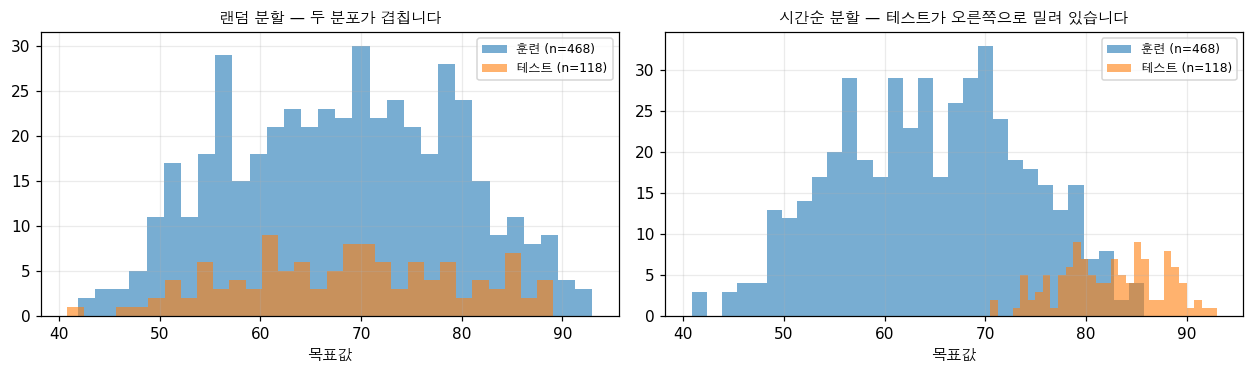

분할                             훈련 범위                테스트 범위       테스트가 범위 밖
----------------------------------------------------------------------------
랜덤                      [41.9, 93.0]          [40.8, 89.1]           0.8%
시간순                     [40.8, 85.7]          [70.5, 93.0]          28.0%

=> 랜덤 분할에서는 테스트 값이 거의 전부 훈련 범위 안에 있습니다.
   시간순 분할에서는 상당수가 훈련 범위를 넘어갑니다.
   이게 '동일 분포' 가정이 깨진다는 1절 이야기의 구체적인 모습입니다.


In [12]:
# ✨ 추가 — 왜 그런지 분포로 보여 줍니다
X훈R, X테R, y훈R, y테R = train_test_split(X, y, test_size=0.2, random_state=0)

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.5))
ax[0].hist(y훈R, bins=30, alpha=0.6, label=f"훈련 (n={len(y훈R)})")
ax[0].hist(y테R, bins=30, alpha=0.6, label=f"테스트 (n={len(y테R)})")
ax[0].set_title("랜덤 분할 — 두 분포가 겹칩니다", fontsize=10)
ax[1].hist(y[:컷], bins=30, alpha=0.6, label=f"훈련 (n={컷})")
ax[1].hist(y[컷:], bins=30, alpha=0.6, label=f"테스트 (n={len(y)-컷})")
ax[1].set_title("시간순 분할 — 테스트가 오른쪽으로 밀려 있습니다", fontsize=10)
for a_ in ax:
    a_.set_xlabel("목표값"); a_.legend(fontsize=8); a_.grid(alpha=0.25)
plt.tight_layout(); plt.show()

print(f"{'분할':<14}{'훈련 범위':>22}{'테스트 범위':>22}{'테스트가 범위 밖':>16}")
print("-" * 76)
for 라벨, y훈, y테 in [("랜덤", y훈R, y테R), ("시간순", y[:컷], y[컷:])]:
    밖 = np.mean((y테 < y훈.min()) | (y테 > y훈.max()))
    print(f"{라벨:<14}{f'[{y훈.min():.1f}, {y훈.max():.1f}]':>22}"
          f"{f'[{y테.min():.1f}, {y테.max():.1f}]':>22}{밖:>15.1%}")

print("\n=> 랜덤 분할에서는 테스트 값이 거의 전부 훈련 범위 안에 있습니다.")
print("   시간순 분할에서는 상당수가 훈련 범위를 넘어갑니다.")
print("   이게 '동일 분포' 가정이 깨진다는 1절 이야기의 구체적인 모습입니다.")

---

## 9. ⚠️ "트리는 추세를 다룬다"는 말의 진위

> 🔗 **앞 절과 이어서** — 8절에서 모델에 따라 부풀림이 다르다는 걸 봤습니다.
> 부스팅과 포레스트가 유독 심했죠. 그 이유를 이 절에서 밝힙니다.

> 📗 원문의 "Common Mistakes" 표에 이런 항목이 있습니다.
>
> | Mistake | How to fix |
> | --- | --- |
> | Not differencing | Tree models handle trends; linear models need stationarity |
>
> (차분을 안 하는 것 → 트리 모델은 추세를 다룹니다. 선형 모델은 정상성이 필요합니다.)

### ⚠️ 측정해 보니 **반대**였습니다

재 보겠습니다. 추세가 있는 계열에 차분을 하기 전과 후로 나눠서요.

In [13]:
import copy

def 차분복원평가(만들기, 원계열, 시차수=14, 비율=0.8):
    # 차분한 계열로 학습하고, 예측을 원래 수준으로 되돌려 같은 척도로 채점합니다
    차분 = np.diff(원계열)
    Xd, yd = 시차특징만들기(차분, 시차수)
    컷d = int(len(Xd) * 비율)
    모델 = 만들기().fit(Xd[:컷d], yd[:컷d])
    변화예측 = 모델.predict(Xd[컷d:])
    # 차분 예측은 '변화량'입니다. 직전 실제값에 더해 수준으로 되돌립니다
    직전 = 원계열[시차수 + 컷d : 시차수 + 컷d + len(변화예측)]
    복원 = 직전 + 변화예측
    실제 = 원계열[시차수 + 컷d + 1 : 시차수 + 컷d + 1 + len(변화예측)]
    R2 = 1 - np.sum((실제-복원)**2) / np.sum((실제-실제.mean())**2)
    return R2, np.mean(np.abs(실제 - 복원))

print(f"{'모델':<20}{'원본 R²':>11}{'원본 MAE':>11}"
      f"{'차분 후 R²':>13}{'차분 후 MAE':>13}{'차분 효과':>11}")
print("-" * 80)
차분표 = []
for 이름, 만들기 in 모델들:
    m = 만들기().fit(X[:컷], y[:컷])
    원R2 = m.score(X[컷:], y[컷:])
    원MAE = np.mean(np.abs(m.predict(X[컷:]) - y[컷:]))
    차R2, 차MAE = 차분복원평가(만들기, 계열)
    차분표.append((이름, 원R2, 원MAE, 차R2, 차MAE))
    print(f"{이름:<20}{원R2:>11.4f}{원MAE:>11.3f}{차R2:>13.4f}{차MAE:>13.3f}"
          f"{차R2-원R2:>+11.4f}")

선형 = 차분표[0]
트리들 = 차분표[1:]
print(f"\n=> ⚠️ 📗 원문의 주장과 방향이 반대입니다.")
print(f"\n   · 선형 모델({선형[0]})은 차분 없이도 R² {선형[1]:.4f} 입니다. "
      f"차분해도 {선형[3]:.4f} 로 거의 그대로입니다 ({선형[3]-선형[1]:+.4f}).")
print(f"     => '선형 모델은 정상성이 필요하다'는 말이 이 데이터에서는 안 맞습니다.")
def 조사(말, 받침있을때, 받침없을때):
    끝 = 말.rstrip(")").rstrip()[-1]
    받침 = (ord(끝) - 0xAC00) % 28 if 0xAC00 <= ord(끝) <= 0xD7A3 else 1
    return 받침있을때 if 받침 else 받침없을때

for 이름, 원R2, 원MAE, 차R2, 차MAE in 트리들:
    print(f"   · {이름}{조사(이름, '은', '는')} 차분 없이 R² {원R2:.4f} 입니다. "
          f"차분하면 {차R2:.4f} 로 뜁니다 ({차R2-원R2:+.4f}).")
print(f"     => '트리 모델은 추세를 다룬다'는 말과 반대입니다. "
      f"트리야말로 차분이 필요합니다.")
print(f"\n   다음 셀에서 이유를 봅니다. 한 줄로 말하면 '트리는 외삽을 못 합니다.'")

모델                        원본 R²     원본 MAE      차분 후 R²     차분 후 MAE      차분 효과
--------------------------------------------------------------------------------
Ridge (선형)               0.9118      1.193       0.9135        1.173    +0.0017
그라디언트 부스팅                0.4857      2.911       0.9040        1.220    +0.4183
랜덤 포레스트                  0.3974      3.168       0.9022        1.275    +0.5048

=> ⚠️ 📗 원문의 주장과 방향이 반대입니다.

   · 선형 모델(Ridge (선형))은 차분 없이도 R² 0.9118 입니다. 차분해도 0.9135 로 거의 그대로입니다 (+0.0017).
     => '선형 모델은 정상성이 필요하다'는 말이 이 데이터에서는 안 맞습니다.
   · 그라디언트 부스팅은 차분 없이 R² 0.4857 입니다. 차분하면 0.9040 로 뜁니다 (+0.4183).
   · 랜덤 포레스트는 차분 없이 R² 0.3974 입니다. 차분하면 0.9022 로 뜁니다 (+0.5048).
     => '트리 모델은 추세를 다룬다'는 말과 반대입니다. 트리야말로 차분이 필요합니다.

   다음 셀에서 이유를 봅니다. 한 줄로 말하면 '트리는 외삽을 못 합니다.'


훈련 목표값 범위  [40.83, 82.30]
테스트 목표값 범위 [68.64, 92.99]   <- 훈련 최대(82.30)를 넘어갑니다

모델                        MAE      예측 최소      예측 최대       훈련 최대 초과?
--------------------------------------------------------------------
Ridge (선형)              1.198      67.95      94.08          넘습니다 ✔
그라디언트 부스팅               3.802      67.14      81.87        못 넘습니다 ✘
랜덤 포레스트                 3.816      67.07      80.42        못 넘습니다 ✘


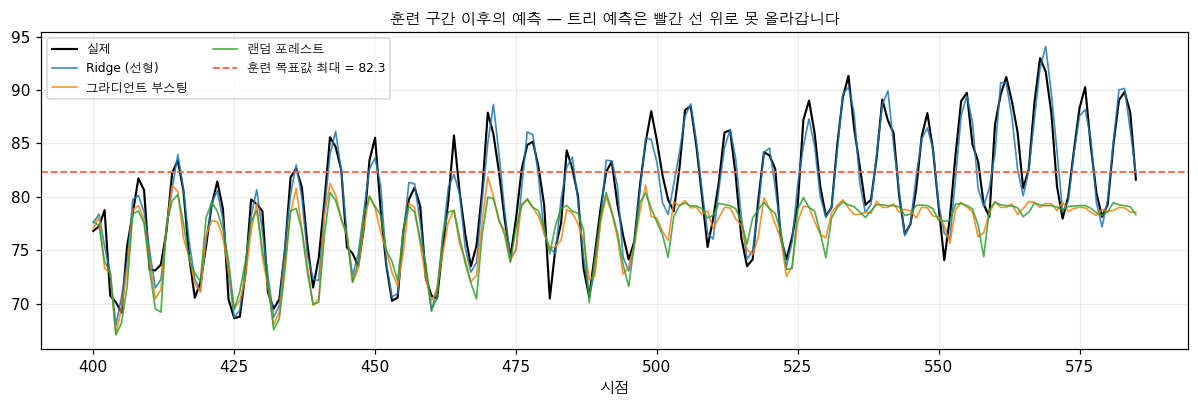


=> 그림의 빨간 점선이 훈련에서 본 가장 큰 값입니다.
   트리 계열의 예측선은 그 위로 절대 올라가지 못합니다.
   선형 모델은 넘어갑니다 (최대 94.08).

   이유는 4단원 트리 구조에 있습니다. 트리의 예측값은 '잎에 담긴 훈련 샘플의 평균'입니다.
   훈련 샘플의 평균은 훈련 샘플의 최댓값을 넘을 수 없습니다. 구조적으로 불가능합니다.
   반면 선형 모델은 y = w·x + b 라는 '식'이라서 x를 밀어 넣으면 계속 올라갑니다.

   💡 그래서 차분이 트리를 살립니다.
      원래 값은 계속 커지지만(50 -> 90), 변화량은 범위가 그대로입니다.
      차분하면 추세가 사라지고, 트리가 '본 적 있는 범위' 안에서만 일하면 됩니다.

   📝 정정하면 이렇게 써야 맞습니다.
      '선형 모델은 추세를 외삽할 수 있습니다. 트리 모델은 못 하므로 차분이 필요합니다.'

   ⚠️ 그리고 📗 원문의 다른 주장도 같이 흔들립니다.
      원문: 'lag features + gradient boosting is the strongest starting point'
      이 데이터에서는 차분 없는 부스팅이 Ridge 보다 MAE 가 2.4배 나쁩니다.
      부스팅이 약한 게 아니라, 차분을 건너뛰면 약해집니다. 순서가 중요합니다.


In [14]:
# ✨ 추가 — 이유: 트리는 훈련에서 본 값의 범위를 벗어난 예측을 할 수 없습니다
훈련끝 = 400
X훈, y훈 = X[:훈련끝], y[:훈련끝]
y테 = y[훈련끝:]

print(f"훈련 목표값 범위  [{y훈.min():.2f}, {y훈.max():.2f}]")
print(f"테스트 목표값 범위 [{y테.min():.2f}, {y테.max():.2f}]   "
      f"<- 훈련 최대({y훈.max():.2f})를 넘어갑니다\n")

print(f"{'모델':<20}{'MAE':>9}{'예측 최소':>11}{'예측 최대':>11}"
      f"{'훈련 최대 초과?':>16}")
print("-" * 68)
예측모음 = {}
for 이름, 만들기 in 모델들:
    m = 만들기().fit(X훈, y훈)
    p = m.predict(X[훈련끝:])
    예측모음[이름] = p
    넘음 = p.max() > y훈.max()
    print(f"{이름:<20}{np.mean(np.abs(y테-p)):>9.3f}{p.min():>11.2f}{p.max():>11.2f}"
          f"{'넘습니다 ✔' if 넘음 else '못 넘습니다 ✘':>16}")

plt.figure(figsize=(11, 3.8))
plt.plot(np.arange(훈련끝, len(y)), y테, lw=1.4, color="black", label="실제")
for 이름, p in 예측모음.items():
    plt.plot(np.arange(훈련끝, len(y)), p, lw=1.1, alpha=0.85, label=이름)
plt.axhline(y훈.max(), color="tomato", ls="--", lw=1.2,
            label=f"훈련 목표값 최대 = {y훈.max():.1f}")
plt.title("훈련 구간 이후의 예측 — 트리 예측은 빨간 선 위로 못 올라갑니다", fontsize=10)
plt.xlabel("시점"); plt.legend(fontsize=8, ncol=2); plt.grid(alpha=0.25)
plt.tight_layout(); plt.show()

print(f"\n=> 그림의 빨간 점선이 훈련에서 본 가장 큰 값입니다.")
print(f"   트리 계열의 예측선은 그 위로 절대 올라가지 못합니다.")
print(f"   선형 모델은 넘어갑니다 (최대 {예측모음['Ridge (선형)'].max():.2f}).")
print(f"\n   이유는 4단원 트리 구조에 있습니다. 트리의 예측값은 '잎에 담긴 훈련 샘플의 평균'입니다.")
print(f"   훈련 샘플의 평균은 훈련 샘플의 최댓값을 넘을 수 없습니다. 구조적으로 불가능합니다.")
print(f"   반면 선형 모델은 y = w·x + b 라는 '식'이라서 x를 밀어 넣으면 계속 올라갑니다.")
print(f"\n   💡 그래서 차분이 트리를 살립니다.")
print(f"      원래 값은 계속 커지지만(50 -> 90), 변화량은 범위가 그대로입니다.")
print(f"      차분하면 추세가 사라지고, 트리가 '본 적 있는 범위' 안에서만 일하면 됩니다.")
print(f"\n   📝 정정하면 이렇게 써야 맞습니다.")
print(f"      '선형 모델은 추세를 외삽할 수 있습니다. 트리 모델은 못 하므로 차분이 필요합니다.'")
print(f"\n   ⚠️ 그리고 📗 원문의 다른 주장도 같이 흔들립니다.")
print(f"      원문: 'lag features + gradient boosting is the strongest starting point'")
print(f"      이 데이터에서는 차분 없는 부스팅이 Ridge 보다 MAE 가 "
      f"{차분표[1][2]/차분표[0][2]:.1f}배 나쁩니다.")
print(f"      부스팅이 약한 게 아니라, 차분을 건너뛰면 약해집니다. 순서가 중요합니다.")

---

## 10. 이겨야 하는 기준선 3개

> 🔗 **앞 절과 이어서** — 9절에서 "부스팅이 Ridge보다 나쁘다"는 걸 봤습니다.
> 그런데 그게 **얼마나** 나쁜 건지는 아직 모릅니다. 비교 대상이 모델뿐이었으니까요.
> 그래서 **아무 학습도 안 한 기준선**이 필요합니다.

> 📗 **원문** — Ship It / "Baselines You Must Beat"

| 기준선 | 예측 방식 | 📗 원문의 설명 |
| --- | --- | --- |
| **마지막 값** (persistence) | 내일은 오늘과 같다 | "surprisingly hard to beat" |
| **계절 나이브** | 오늘은 지난주 같은 요일과 같다 | 이걸 못 넘으면 계절성 말고 배운 게 없다는 뜻 |
| **이동 평균** | 최근 k개의 평균 | 잡음은 줄지만 급변을 못 따라갑니다 |

> 📗 원문: "If your fancy ML model loses to the seasonal naive baseline, you have a bug.
> Most commonly: future leakage in features, wrong evaluation method,
> or the series is truly random."

이 말이 맞는지 보겠습니다.

In [15]:
from sklearn.metrics import mean_absolute_error

테스트시작 = 컷 + 14          # X 의 인덱스를 원계열 인덱스로 환산
실제값 = 계열[테스트시작:]

# 기준선 ①: 마지막 값 — 직전 값을 그대로
기준_마지막 = 계열[테스트시작-1:-1]

# 기준선 ②: 계절 나이브 — 7일 전 값
기준_계절 = 계열[테스트시작-7:-7]

# 기준선 ③: 이동 평균 — 직전 7개의 평균
기준_이동 = np.array([계열[i-7:i].mean() for i in range(테스트시작, len(계열))])

print(f"{'방법':<26}{'MAE':>9}{'RMSE':>9}  비고")
print("-" * 62)
행들 = []
for 라벨, 예측, 비고 in [
        ("기준선 ① 마지막 값", 기준_마지막, "학습 없음"),
        ("기준선 ② 계절 나이브(7일)", 기준_계절, "학습 없음"),
        ("기준선 ③ 이동 평균(7일)", 기준_이동, "학습 없음"),
]:
    mae = mean_absolute_error(실제값, 예측)
    rmse = np.sqrt(np.mean((실제값-예측)**2))
    행들.append((라벨, mae, rmse))
    print(f"{라벨:<25}{mae:>9.3f}{rmse:>9.3f}  {비고}")

print()
for 이름, 만들기 in 모델들:
    m = 만들기().fit(X[:컷], y[:컷])
    p = m.predict(X[컷:])
    mae = mean_absolute_error(y[컷:], p)
    rmse = np.sqrt(np.mean((y[컷:]-p)**2))
    행들.append((이름, mae, rmse))
    print(f"{이름:<25}{mae:>9.3f}{rmse:>9.3f}  시차 14개로 학습")

# 차분한 부스팅도 넣습니다 (9절의 교훈 적용)
차R2, 차MAE = 차분복원평가(lambda: GradientBoostingRegressor(random_state=0), 계열)
print(f"{'부스팅 + 차분 (9절)':<25}{차MAE:>9.3f}{'-':>9}  차분 후 학습")

최고기준 = min(행들[:3], key=lambda r: r[1])
print(f"\n=> 가장 센 기준선은 '{최고기준[0]}' 으로 MAE {최고기준[1]:.3f} 입니다.")
짐 = [r for r in 행들[3:] if r[1] > 최고기준[1]]
이김 = [r for r in 행들[3:] if r[1] <= 최고기준[1]]
print(f"   기준선을 넘은 모델: {len(이김)}개 / 못 넘은 모델: {len(짐)}개")
for 이름, mae, _ in 짐:
    print(f"      ✘ {이름} (MAE {mae:.3f}) — 기준선보다 {mae-최고기준[1]:+.3f} 나쁩니다")
print(f"\n   ⚠️ 📗 원문은 '계절 나이브에 지면 버그다' 라고 했습니다.")
print(f"      여기서 트리 모델들이 집니다. 그런데 버그는 아닙니다.")
print(f"      9절에서 본 외삽 불가 문제입니다. 차분하면 바로 넘어갑니다 "
      f"(MAE {차MAE:.3f}).")
print(f"\n   💡 그래서 📗 원문의 조언을 이렇게 쓰는 게 낫습니다.")
print(f"      '기준선에 지면 멈추고 원인을 찾으세요. 버그일 수도, 전처리 누락일 수도 있습니다.'")
print(f"      실제로 기준선은 그 자체로 쓸모가 있는 게 아니라 "
      f"'내 모델이 뭘 놓쳤나'를 알려주는 진단 도구입니다.")

방법                              MAE     RMSE  비고
--------------------------------------------------------------
기준선 ① 마지막 값                  3.513    3.980  학습 없음
기준선 ② 계절 나이브(7일)             2.360    2.892  학습 없음
기준선 ③ 이동 평균(7일)              3.959    4.563  학습 없음

Ridge (선형)                   1.193    1.496  시차 14개로 학습
그라디언트 부스팅                    2.911    3.611  시차 14개로 학습
랜덤 포레스트                      3.168    3.909  시차 14개로 학습
부스팅 + 차분 (9절)                1.220        -  차분 후 학습

=> 가장 센 기준선은 '기준선 ② 계절 나이브(7일)' 으로 MAE 2.360 입니다.
   기준선을 넘은 모델: 1개 / 못 넘은 모델: 2개
      ✘ 그라디언트 부스팅 (MAE 2.911) — 기준선보다 +0.551 나쁩니다
      ✘ 랜덤 포레스트 (MAE 3.168) — 기준선보다 +0.808 나쁩니다

   ⚠️ 📗 원문은 '계절 나이브에 지면 버그다' 라고 했습니다.
      여기서 트리 모델들이 집니다. 그런데 버그는 아닙니다.
      9절에서 본 외삽 불가 문제입니다. 차분하면 바로 넘어갑니다 (MAE 1.220).

   💡 그래서 📗 원문의 조언을 이렇게 쓰는 게 낫습니다.
      '기준선에 지면 멈추고 원인을 찾으세요. 버그일 수도, 전처리 누락일 수도 있습니다.'
      실제로 기준선은 그 자체로 쓸모가 있는 게 아니라 '내 모델이 뭘 놓쳤나'를 알려주는 진단 도구입니다.


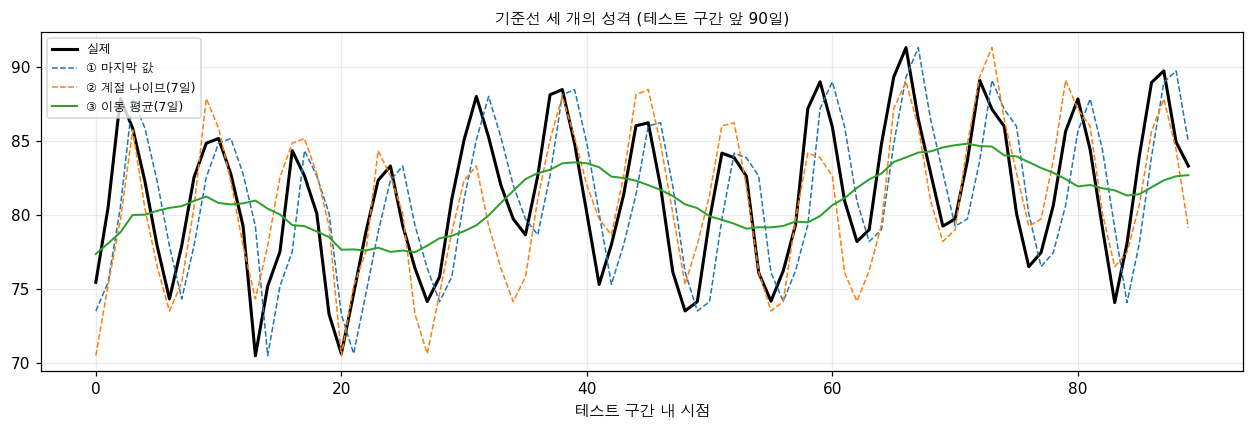

=> 각 기준선이 틀리는 방식이 다릅니다.
   ① 마지막 값: 실제를 한 칸 늦게 따라갑니다. 주기가 있으면 항상 늦습니다
   ② 계절 나이브: 주기를 정확히 맞춥니다. 추세만큼 아래로 깔립니다
   ③ 이동 평균: 평평합니다. 주기를 평균으로 지워 버렸습니다

   계절 나이브가 이기는 이유가 보이시죠. 이 계열의 지배적 구조가 7일 주기라서입니다.
   📗 원문: '주기가 뚜렷한 데이터에서는 계절 나이브가 넘기 어렵다'

   💡 기준선 선택은 데이터를 보고 하세요.
      주기가 뚜렷하면 계절 나이브, 관성이 강하면 마지막 값, 잡음이 크면 이동 평균입니다.


In [16]:
# ✨ 추가 — 기준선들이 각각 어떻게 틀리는지 그림으로
구간 = slice(0, 90)
plt.figure(figsize=(11.5, 4))
plt.plot(실제값[구간], lw=2.0, color="black", label="실제")
plt.plot(기준_마지막[구간], lw=1.0, ls="--", label="① 마지막 값")
plt.plot(기준_계절[구간], lw=1.0, ls="--", label="② 계절 나이브(7일)")
plt.plot(기준_이동[구간], lw=1.3, label="③ 이동 평균(7일)")
plt.title("기준선 세 개의 성격 (테스트 구간 앞 90일)", fontsize=10)
plt.xlabel("테스트 구간 내 시점"); plt.legend(fontsize=8); plt.grid(alpha=0.25)
plt.tight_layout(); plt.show()

print("=> 각 기준선이 틀리는 방식이 다릅니다.")
print("   ① 마지막 값: 실제를 한 칸 늦게 따라갑니다. 주기가 있으면 항상 늦습니다")
print("   ② 계절 나이브: 주기를 정확히 맞춥니다. 추세만큼 아래로 깔립니다")
print("   ③ 이동 평균: 평평합니다. 주기를 평균으로 지워 버렸습니다")
print(f"\n   계절 나이브가 이기는 이유가 보이시죠. 이 계열의 지배적 구조가 7일 주기라서입니다.")
print(f"   📗 원문: '주기가 뚜렷한 데이터에서는 계절 나이브가 넘기 어렵다'")
print(f"\n   💡 기준선 선택은 데이터를 보고 하세요.")
print(f"      주기가 뚜렷하면 계절 나이브, 관성이 강하면 마지막 값, 잡음이 크면 이동 평균입니다.")

---

## 11. 평가 지표: MAE · RMSE · MAPE

> 🔗 **앞 절과 이어서** — 10절에서 MAE와 RMSE를 썼습니다.
> 둘이 다른 답을 줄 수도 있고, 세 번째 지표인 MAPE는 아예 터질 수도 있습니다. 정리합니다.

> 📗 **원문** — "Evaluation Metrics"

| 지표 | 정의 | 성격 | 📗 원문의 표현 |
| --- | --- | --- | --- |
| **MAE** | 오차 절댓값의 평균 | 원래 단위로 읽힙니다 | "predictions are off by 3.2 degrees" |
| **RMSE** | 제곱 오차 평균의 제곱근 | 큰 오차를 더 세게 벌줍니다 | "use when big errors are worse" |
| **MAPE** | \|오차/실제값\| 의 평균 × 100 | 척도에 무관 | "undefined when true values are zero" |

### 🧸 언제 뭘 쓰나

- 배달 예상 시간: **MAE**. "평균 3분 틀립니다"가 바로 이해됩니다
- 재고 예측: **RMSE**. 100개 틀리는 사고 한 번이 1개 틀리는 100번보다 치명적입니다
- 여러 지점 매출 비교: **MAPE**. 규모가 달라도 비교됩니다. **단, 0이 없을 때만**

In [17]:
def 세지표(실제, 예측):
    mae = np.mean(np.abs(실제-예측))
    rmse = np.sqrt(np.mean((실제-예측)**2))
    with np.errstate(divide="ignore", invalid="ignore"):
        mape = np.mean(np.abs((실제-예측)/실제)) * 100
    return mae, rmse, mape

print("① 같은 MAE, 다른 RMSE — 오차가 몰려 있는지 퍼져 있는지\n")
실제샘플 = np.full(10, 100.0)
고르게 = 실제샘플 + np.array([2, -2, 2, -2, 2, -2, 2, -2, 2, -2], dtype=float)
몰려서 = 실제샘플 + np.array([0, 0, 0, 0, 0, 0, 0, 0, 0, 20], dtype=float)
print(f"{'경우':<24}{'MAE':>9}{'RMSE':>9}{'RMSE/MAE':>11}")
print("-" * 54)
for 라벨, 예 in [("매번 2씩 틀림", 고르게), ("아홉 번 정확, 한 번 20 틀림", 몰려서)]:
    mae, rmse, _ = 세지표(실제샘플, 예)
    print(f"{라벨:<23}{mae:>9.3f}{rmse:>9.3f}{rmse/mae:>11.3f}")
print("\n   => MAE가 똑같이 2.0 입니다. 그런데 RMSE는 2.0 vs 6.3 입니다.")
print("      '큰 사고 한 번'이 문제라면 RMSE를 봐야 합니다.")
print("      RMSE/MAE 비율이 1에 가까우면 오차가 고르고, 크면 몰려 있다는 뜻입니다.")

print("\n\n② MAPE 가 터지는 지점\n")
실제0 = np.array([10.0, 5.0, 0.0, -2.0, 8.0])
예측0 = np.array([11.0, 4.0, 1.0, -1.0, 7.0])
mae, rmse, mape = 세지표(실제0, 예측0)
print(f"   실제값 {실제0}")
print(f"   예측값 {예측0}   (전부 1씩 틀렸습니다)")
print(f"\n   MAE  = {mae:.3f}   <- 정상")
print(f"   RMSE = {rmse:.3f}   <- 정상")
print(f"   MAPE = {mape}   <- 터집니다")
print("\n   => 실제값에 0이 있으면 0으로 나누게 됩니다. 📗 원문의 'undefined' 가 이겁니다.")
print("      ⚠️ 그리고 음수가 있으면 '퍼센트 오차'라는 말 자체가 의미를 잃습니다.")
print("      재고, 판매량, 방문자 수처럼 0이 흔한 데이터에는 MAPE 를 쓰지 마세요.")
print("      대안: sMAPE, MASE(기준선 대비 상대 오차) 가 있습니다.")

print("\n\n③ 이 단원 계열에 세 지표를 다 적용\n")
print(f"{'방법':<26}{'MAE':>9}{'RMSE':>9}{'MAPE':>9}")
print("-" * 54)
for 라벨, 예측 in [("계절 나이브(7일)", 기준_계절), ("마지막 값", 기준_마지막)]:
    mae, rmse, mape = 세지표(실제값, 예측)
    print(f"{라벨:<25}{mae:>9.3f}{rmse:>9.3f}{mape:>8.2f}%")
for 이름, 만들기 in 모델들[:2]:
    m = 만들기().fit(X[:컷], y[:컷]); p = m.predict(X[컷:])
    mae, rmse, mape = 세지표(y[컷:], p)
    print(f"{이름:<25}{mae:>9.3f}{rmse:>9.3f}{mape:>8.2f}%")
print("\n   => 이 계열은 값이 50~93 사이라 0이 없습니다. MAPE 가 잘 계산됩니다.")
print("      세 지표가 같은 순위를 줍니다. 순위가 갈릴 때만 어느 지표가 맞는지 고민하면 됩니다.")
print("      9단원 2절에서 본 '지표는 목적에 따라 고른다'가 여기서도 그대로입니다.")

① 같은 MAE, 다른 RMSE — 오차가 몰려 있는지 퍼져 있는지

경우                            MAE     RMSE   RMSE/MAE
------------------------------------------------------
매번 2씩 틀림                   2.000    2.000      1.000
아홉 번 정확, 한 번 20 틀림         2.000    6.325      3.162

   => MAE가 똑같이 2.0 입니다. 그런데 RMSE는 2.0 vs 6.3 입니다.
      '큰 사고 한 번'이 문제라면 RMSE를 봐야 합니다.
      RMSE/MAE 비율이 1에 가까우면 오차가 고르고, 크면 몰려 있다는 뜻입니다.


② MAPE 가 터지는 지점

   실제값 [10.  5.  0. -2.  8.]
   예측값 [11.  4.  1. -1.  7.]   (전부 1씩 틀렸습니다)

   MAE  = 1.000   <- 정상
   RMSE = 1.000   <- 정상
   MAPE = inf   <- 터집니다

   => 실제값에 0이 있으면 0으로 나누게 됩니다. 📗 원문의 'undefined' 가 이겁니다.
      ⚠️ 그리고 음수가 있으면 '퍼센트 오차'라는 말 자체가 의미를 잃습니다.
      재고, 판매량, 방문자 수처럼 0이 흔한 데이터에는 MAPE 를 쓰지 마세요.
      대안: sMAPE, MASE(기준선 대비 상대 오차) 가 있습니다.


③ 이 단원 계열에 세 지표를 다 적용

방법                              MAE     RMSE     MAPE
------------------------------------------------------
계절 나이브(7일)                   2.360    2.892    2.88%
마지막 값                        3.513    3.980    4.30%


---

## 12. ⚠️ 롤링 특징과 달력 특징

> 🔗 **앞 절과 이어서** — 10절에서 기준선을 못 넘는 모델을 봤고,
> 11절에서 재는 법을 정했습니다. 이제 특징을 늘려 성능을 올려 볼 차례입니다. 📗 연습문제 4번입니다.

> 📗 원문의 주장: "These give the model information about recent trends and volatility
> that lag features alone do not capture."
>
> (롤링 통계는 시차 특징만으로는 **못 잡는** 최근 추세·변동성 정보를 줍니다.)

📗 연습문제 4번이 "롤링 평균(7), 롤링 표준편차(7), 요일 특징을 더해 비교하라"고 합니다.
그대로 해 보겠습니다.

In [18]:
def 특징만들기(롤링=False, 달력=False, 시차수=14):
    열들 = [np.roll(계열, i) for i in range(1, 시차수+1)]      # 시차 1..시차수
    이름들 = [f"lag{i}" for i in range(1, 시차수+1)]
    if 롤링:
        for 창 in (7, 14):
            열들.append(np.array([계열[max(0, i-창):i].mean() for i in range(n)]))
            열들.append(np.array([계열[max(0, i-창):i].std() if i > 1 else 0.0
                                 for i in range(n)]))
            이름들 += [f"롤링평균{창}", f"롤링표준{창}"]
    if 달력:
        # 요일을 원-핫이 아니라 사인/코사인으로 (8단원 9절의 순환 인코딩)
        열들 += [np.sin(2*np.pi*(t % 7)/7), np.cos(2*np.pi*(t % 7)/7)]
        이름들 += ["요일sin", "요일cos"]
    XX = np.column_stack(열들)[시차수:]
    yy = 계열[시차수:]
    return XX, yy, 이름들

print(f"{'특징 구성':<20}{'개수':>5}{'Ridge MAE':>12}{'부스팅 MAE':>13}"
      f"{'Ridge 변화':>13}{'부스팅 변화':>14}")
print("-" * 80)
기준MAE = {}
for 라벨, 롤, 달 in [("시차만", False, False), ("시차+롤링", True, False),
                   ("시차+달력", False, True), ("시차+롤링+달력", True, True)]:
    XX, yy, 이름들 = 특징만들기(롤, 달)
    c = int(len(XX)*0.8)
    줄 = f"{라벨:<20}{XX.shape[1]:>5}"
    변화문 = ""
    for 키, 만들기 in [("Ridge", lambda: Ridge(alpha=1.0)),
                     ("부스팅", lambda: GradientBoostingRegressor(random_state=0))]:
        m = 만들기().fit(XX[:c], yy[:c])
        mae = np.mean(np.abs(m.predict(XX[c:]) - yy[c:]))
        if 라벨 == "시차만":
            기준MAE[키] = mae
        줄 += f"{mae:>12.3f}" if 키 == "Ridge" else f"{mae:>13.3f}"
        변화문 += (f"{mae-기준MAE[키]:>+13.3f}" if 키 == "Ridge"
                 else f"{mae-기준MAE[키]:>+14.3f}")
    print(줄 + 변화문)

print("\n=> ⚠️ 📗 원문의 주장이 반쪽만 맞습니다.")
print("\n   · 롤링 특징: 두 모델 모두 나빠집니다 (아주 조금). 도움이 안 됩니다")
print("   · 달력 특징: 두 모델 모두 좋아집니다. 이건 확실한 이득입니다")
print("\n   롤링이 왜 소용없나요? 수학적으로 당연합니다.")
print("   롤링 평균(7) = (lag1 + lag2 + ... + lag7) / 7 입니다.")
print("   시차 특징들의 선형 결합입니다. Ridge 는 선형 모델이니 이미 만들 수 있는 값이죠.")
print("   새 정보가 0 입니다. 열만 늘어서 추정할 계수가 많아지니 아주 조금 나빠집니다.")
print("\n   📗 원문도 뒤에서 이걸 암시합니다. '이런 무늬는 트리 모델이 배울 수 있고 선형은 못 한다'")
print("   그런데 부스팅에서도 안 좋아졌습니다. 시차 14개에 이미 정보가 다 있어서입니다.")
print("\n   달력은 왜 되나요? 시차 특징으로 만들 수 없는 정보이기 때문입니다.")
print("   '지금이 몇 번째 요일인가'는 과거 값들의 함수가 아닙니다. 외부에서 들어온 정보죠.")
print("\n   💡 특징 추가의 판단 기준이 여기서 나옵니다.")
print("      '이 특징을 기존 특징들로 계산할 수 있나?' 를 먼저 물어 보세요.")
print("      계산할 수 있으면 선형 모델에는 확실히 무용이고, 트리에도 보통 무용입니다.")
print("      계산할 수 없으면(달력, 날씨, 프로모션 여부) 그게 진짜 새 정보입니다.")

특징 구성                  개수   Ridge MAE      부스팅 MAE     Ridge 변화        부스팅 변화
--------------------------------------------------------------------------------
시차만                    14       1.193        2.911       +0.000        +0.000
시차+롤링                  18       1.197        2.955       +0.004        +0.044
시차+달력                  16       1.129        2.735       -0.064        -0.176
시차+롤링+달력               20       1.136        2.742       -0.058        -0.169

=> ⚠️ 📗 원문의 주장이 반쪽만 맞습니다.

   · 롤링 특징: 두 모델 모두 나빠집니다 (아주 조금). 도움이 안 됩니다
   · 달력 특징: 두 모델 모두 좋아집니다. 이건 확실한 이득입니다

   롤링이 왜 소용없나요? 수학적으로 당연합니다.
   롤링 평균(7) = (lag1 + lag2 + ... + lag7) / 7 입니다.
   시차 특징들의 선형 결합입니다. Ridge 는 선형 모델이니 이미 만들 수 있는 값이죠.
   새 정보가 0 입니다. 열만 늘어서 추정할 계수가 많아지니 아주 조금 나빠집니다.

   📗 원문도 뒤에서 이걸 암시합니다. '이런 무늬는 트리 모델이 배울 수 있고 선형은 못 한다'
   그런데 부스팅에서도 안 좋아졌습니다. 시차 14개에 이미 정보가 다 있어서입니다.

   달력은 왜 되나요? 시차 특징으로 만들 수 없는 정보이기 때문입니다.
   '지금이 몇 번째 요일인가'는 과거 값들의 함수가 아닙니다. 외부에서 들어온 정보죠.

   💡 특징 추가의 판단 기준이 여기서 나옵니다.
    

In [19]:
# ✨ 추가 — 롤링 평균이 정말 시차들의 선형 결합인지 확인합니다
XX, yy, 이름들 = 특징만들기(롤링=True, 달력=False)
롤링평균7열 = 이름들.index("롤링평균7")
시차열들 = list(range(7))                       # lag1..lag7

# 롤링평균7 을 lag1..lag7 로 최소제곱 근사해 봅니다
A = XX[:, 시차열들]
b = XX[:, 롤링평균7열]
해, *_ = np.linalg.lstsq(np.column_stack([np.ones(len(A)), A]), b, rcond=None)
근사 = np.column_stack([np.ones(len(A)), A]) @ 해
R2 = 1 - np.sum((b-근사)**2) / np.sum((b-b.mean())**2)

print("롤링평균7 을 lag1~lag7 의 선형 결합으로 맞춰 봅니다")
print(f"   절편 {해[0]:>8.5f}")
for i, 계수 in enumerate(해[1:], 1):
    print(f"   lag{i} 계수 {계수:>8.5f}   (이론값 1/7 = {1/7:.5f})")
print(f"\n   R² = {R2:.10f}")
print(f"   잔차 최대 절댓값 = {np.abs(b-근사).max():.2e}")
print(f"\n=> 계수가 전부 1/7 이고 R² 가 1.0 입니다. 완벽한 선형 결합입니다.")
print(f"   즉 롤링평균7 열은 Ridge 에게 정보량이 정확히 0 입니다.")
print(f"   8단원에서 배운 '다중공선성'의 교과서적 사례이기도 합니다.")

롤링평균7 을 lag1~lag7 의 선형 결합으로 맞춰 봅니다
   절편 -0.00000
   lag1 계수  0.14286   (이론값 1/7 = 0.14286)
   lag2 계수  0.14286   (이론값 1/7 = 0.14286)
   lag3 계수  0.14286   (이론값 1/7 = 0.14286)
   lag4 계수  0.14286   (이론값 1/7 = 0.14286)
   lag5 계수  0.14286   (이론값 1/7 = 0.14286)
   lag6 계수  0.14286   (이론값 1/7 = 0.14286)
   lag7 계수  0.14286   (이론값 1/7 = 0.14286)

   R² = 1.0000000000
   잔차 최대 절댓값 = 1.08e-12

=> 계수가 전부 1/7 이고 R² 가 1.0 입니다. 완벽한 선형 결합입니다.
   즉 롤링평균7 열은 Ridge 에게 정보량이 정확히 0 입니다.
   8단원에서 배운 '다중공선성'의 교과서적 사례이기도 합니다.


---

## 13. SimpleAR 직접 구현

> 🔗 **앞 절과 이어서** — 12절까지 특징을 정리했습니다.
> 이제 모델을 손으로 만들어 봅니다. 놀랍게도 새로 배울 게 없습니다.

> 📗 **원문** — "Build It" / "Simple Autoregressive Model"
>
> 📗 원문: "A pure AR model is just linear regression on lag features...
> This is conceptually identical to linear regression from Lesson 02,
> but applied to time-lagged versions of the same variable."

### 📐 AR 모델이란

**AR(p)** 는 "과거 p개 값의 가중 합으로 다음 값을 예측" 하는 모델입니다.

$$\hat{y}_t = b + w_1 y_{t-1} + w_2 y_{t-2} + \cdots + w_p y_{t-p}$$

2단원의 $\hat{y} = b + w_1 x_1 + \cdots + w_p x_p$ 와 **완전히 같은 식**입니다.
$x$ 자리에 과거의 $y$ 가 들어간 것뿐이죠.

In [20]:
# 📗 원문의 SimpleAR 을 그대로 옮깁니다
class 단순AR:
    def __init__(self, 시차수=5):
        self.시차수 = 시차수
        self.가중치 = None
        self.절편 = None

    def fit(self, 계열값):
        Xf, yf = 시차특징만들기(계열값, self.시차수)
        # 정규방정식 대신 lstsq (수치적으로 더 안정적입니다 — Phase 1 13단원)
        X절편 = np.column_stack([np.ones(len(Xf)), Xf])
        세타 = np.linalg.lstsq(X절편, yf, rcond=None)[0]
        self.절편 = 세타[0]
        self.가중치 = 세타[1:]
        return self

    def predict(self, Xf):
        return self.절편 + Xf @ self.가중치

    def 한걸음(self, 최근값들):
        # 최근값들은 [y_{t-1}, y_{t-2}, ...] 순서입니다
        return self.절편 + np.dot(self.가중치, 최근값들[:self.시차수])


# sklearn 의 선형 회귀와 정말 같은지 확인합니다
from sklearn.linear_model import LinearRegression

훈련계열 = 계열[:int(len(계열)*0.8)]
내AR = 단순AR(시차수=14).fit(훈련계열)
X훈련, y훈련 = 시차특징만들기(훈련계열, 14)
sk = LinearRegression().fit(X훈련, y훈련)

print(f"절편      내 것 {내AR.절편:>10.6f}   sklearn {sk.intercept_:>10.6f}   "
      f"차이 {abs(내AR.절편-sk.intercept_):.2e}")
print(f"가중치 최대 차이 {np.abs(내AR.가중치 - sk.coef_).max():.2e}")
print(f"\n=> 같습니다. 📗 원문 말대로 AR 모델은 '시차 특징 위의 선형 회귀' 입니다.\n")

print(f"{'시차':>5}{'가중치':>12}  해석")
print("-" * 46)
for i, w in enumerate(내AR.가중치, 1):
    막대 = "#" * int(abs(w)*40)
    print(f"{i:>5}{w:>12.4f}  {막대}")
큰것 = int(np.argmax(np.abs(내AR.가중치))) + 1
print(f"\n=> 가중치가 가장 큰 시차는 {큰것} 입니다 ({내AR.가중치[큰것-1]:.4f}).")

# ✨ 추가 — PACF 와 AR 가중치의 정확한 관계를 확인합니다
print(f"\n[PACF 와 AR 가중치는 어떤 관계인가]")
print(f"흔히 '같은 것'이라고 하는데, 정확히는 이렇습니다.")
print(f"(4절의 PACF 와 맞춰 보려고 여기서는 차분계열 로 AR 을 적합합니다.")
print(f" 위 표의 가중치는 원계열로 적합한 것이라 숫자가 다릅니다.)")
print(f"\n{'k':>4}{'PACF(k)':>11}{'AR(k)의 마지막 계수':>22}{'차이':>9}"
      f"{'AR(14)의 k번째 계수':>22}")
print("-" * 70)
AR14 = 단순AR(시차수=14).fit(차분계열)
for k in range(1, 9):
    ARk = 단순AR(시차수=k).fit(차분계열)
    print(f"{k:>4}{내PACF[k]:>11.4f}{ARk.가중치[-1]:>22.4f}"
          f"{abs(내PACF[k]-ARk.가중치[-1]):>9.4f}{AR14.가중치[k-1]:>22.4f}")

print(f"\n=> PACF(k) 는 AR(k) 를 적합했을 때의 마지막 계수 입니다. 두 열이 거의 같죠.")
print(f"   (완전히 같지 않은 건 PACF 가 율-워커 방식이고 내 AR 은 최소제곱이라서입니다)")
print(f"\n   ⚠️ AR(14) 의 k번째 계수와는 전혀 다릅니다. 맨 오른쪽 열을 보세요.")
print(f"      시차 1 에서 PACF 는 {내PACF[1]:+.4f} 인데 AR(14) 의 1번 계수는 "
      f"{AR14.가중치[0]:+.4f} 입니다. 부호까지 반대입니다.")
print(f"      시차 14개를 같이 넣으면 서로 정보를 나눠 가지면서 계수가 재배분됩니다.")
print(f"\n   💡 그래서 'PACF 를 보고 AR 차수 p 를 정한다'는 말이 성립합니다.")
print(f"      PACF(k) 가 유의하지 않아지는 k 가 'AR(k) 를 늘려도 새로 얻을 게 없는 지점'이니까요.")
print(f"      14절에서 ARIMA 의 p 를 고를 때 쓰는 논리가 이것입니다.")

절편      내 것   0.578919   sklearn   0.578919   차이 2.61e-13
가중치 최대 차이 8.16e-15

=> 같습니다. 📗 원문 말대로 AR 모델은 '시차 특징 위의 선형 회귀' 입니다.

   시차         가중치  해석
----------------------------------------------
    1      0.4638  ##################
    2      0.2526  ##########
    3      0.1321  #####
    4      0.0924  ###
    5      0.0803  ###
    6      0.2179  ########
    7      0.1085  ####
    8     -0.1520  ######
    9     -0.0937  ###
   10     -0.3172  ############
   11     -0.1820  #######
   12     -0.0244  
   13      0.1596  ######
   14      0.2552  ##########

=> 가중치가 가장 큰 시차는 1 입니다 (0.4638).

[PACF 와 AR 가중치는 어떤 관계인가]
흔히 '같은 것'이라고 하는데, 정확히는 이렇습니다.
(4절의 PACF 와 맞춰 보려고 여기서는 차분계열 로 AR 을 적합합니다.
 위 표의 가중치는 원계열로 적합한 것이라 숫자가 다릅니다.)

   k    PACF(k)         AR(k)의 마지막 계수       차이        AR(14)의 k번째 계수
----------------------------------------------------------------------
   1     0.4509                0.4528   0.0019               -0.5454
   2    -0.4822               -0.4861   0.0039      

   시차 수      훈련 MAE      테스트 MAE        차이      훈련 샘플      샘플/특징  상태
----------------------------------------------------------------------------------
      1       3.354        3.453    +0.099        479      479.0  과소적합
      2       2.768        3.125    +0.358        478      239.0  과소적합
      3       2.510        2.617    +0.107        477      159.0  과소적합
      5       1.558        1.384    -0.173        476       95.2  과소적합
      7       1.432        1.368    -0.064        474       67.7  과소적합
     14       1.135        1.193    +0.058        468       33.4  과소적합
     21       1.002        1.064    +0.062        463       22.0  
     30       0.918        0.916    -0.002        456       15.2  
     50       0.894        0.903    +0.010        440        8.8  <- 최고
     80       0.850        0.910    +0.060        416        5.2  
    120       0.814        1.022    +0.207        384        3.2  과적합
    180       0.680        1.274    +0.594        336        1.9  과적합
    250  

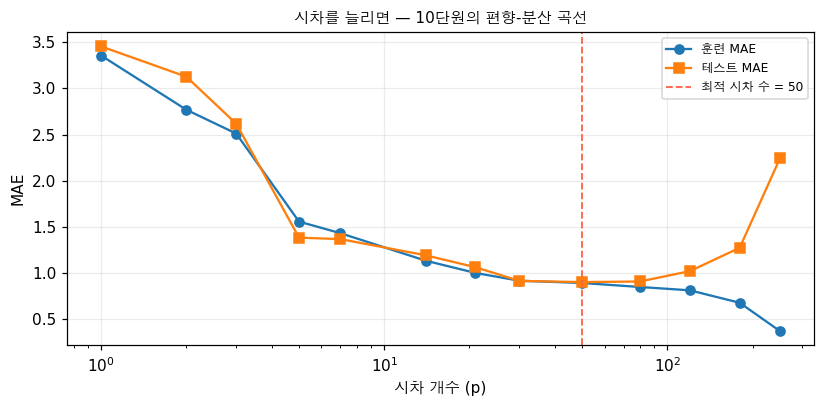


=> 최적 시차 수는 50 이고 테스트 MAE 0.903 입니다.

   왼쪽 끝(편향이 큰 쪽): 시차 1~2 는 주간 주기를 담을 수 없어 나쁩니다.
      시차 1 의 테스트 MAE 3.453 가 최적(0.903)보다 3.8배 나쁩니다.
   오른쪽 끝(분산이 큰 쪽): 시차 250 에서 훈련 MAE 는 0.372 까지 내려가는데
      테스트는 2.244 로 올라갑니다. 외우기 시작한 겁니다.
      훈련 샘플이 280개인데 특징이 250개입니다 (샘플/특징 = 1.1).

   ⚠️ 그런데 최적이 50 입니다. 4절의 ACF 는 '시차 7, 14가 크다'고 했는데
      실제로는 그보다 훨씬 많이 쓰는 게 좋습니다.
      ACF 는 '어디에 신호가 있나'를 알려주지 '몇 개를 쓰면 되나'를 알려주지 않습니다.
      이 계열에는 30일 주기도 넣어 뒀으니, 그걸 담으려면 시차 30 이상이 필요하죠.
      => 📗 원문의 'ACF로 시차 개수를 정하라'는 출발점으로만 쓰고,
         최종 개수는 이렇게 검증 곡선으로 고르세요 (12단원의 탐색).

   📗 원문: 'More lags give the model more history but also more features to fit,
   increasing the risk of overfitting.' 이 말 자체는 정확히 재현됩니다.


In [21]:
# 시차 개수를 바꿔 가며 — 10단원의 편향-분산이 여기서도 나옵니다
# 먼저 전부 계산한 뒤에 찍습니다. 계산하면서 '최고'를 표시하면
# 그 시점까지의 최솟값이라 모든 줄에 표시가 붙습니다
기록 = []
for p in (1, 2, 3, 5, 7, 14, 21, 30, 50, 80, 120, 180, 250):
    Xp, yp = 시차특징만들기(계열, p)
    cp = int(len(Xp)*0.8)
    m = Ridge(alpha=1e-8).fit(Xp[:cp], yp[:cp])     # 거의 순수 최소제곱
    훈 = np.mean(np.abs(m.predict(Xp[:cp]) - yp[:cp]))
    테 = np.mean(np.abs(m.predict(Xp[cp:]) - yp[cp:]))
    기록.append((p, 훈, 테, cp))

최적 = min(기록, key=lambda r: r[2])
print(f"{'시차 수':>7}{'훈련 MAE':>12}{'테스트 MAE':>13}{'차이':>10}"
      f"{'훈련 샘플':>11}{'샘플/특징':>11}  상태")
print("-" * 82)
for p, 훈, 테, cp in 기록:
    # 최적 지점보다 오른쪽에서 테스트가 훈련보다 많이 나쁠 때만 과적합입니다.
    # 왼쪽(시차가 적은 쪽)에서 벌어지는 건 과소적합이라 라벨을 따로 붙입니다
    if p == 최적[0]:
        표시 = "<- 최고"
    elif p < 최적[0] and 테 > 최적[2] * 1.3:
        표시 = "과소적합"
    elif p > 최적[0] and 테 > 훈 * 1.1:
        표시 = "과적합"
    else:
        표시 = ""
    print(f"{p:>7}{훈:>12.3f}{테:>13.3f}{테-훈:>+10.3f}{cp:>11}{cp/p:>11.1f}  {표시}")
plt.figure(figsize=(7.6, 3.8))
plt.plot([r[0] for r in 기록], [r[1] for r in 기록], "o-", label="훈련 MAE")
plt.plot([r[0] for r in 기록], [r[2] for r in 기록], "s-", label="테스트 MAE")
plt.xscale("log")
plt.axvline(최적[0], color="tomato", ls="--", lw=1.2, label=f"최적 시차 수 = {최적[0]}")
plt.xlabel("시차 개수 (p)"); plt.ylabel("MAE"); plt.legend(fontsize=8); plt.grid(alpha=0.25)
plt.title("시차를 늘리면 — 10단원의 편향-분산 곡선", fontsize=10)
plt.tight_layout(); plt.show()

마지막 = 기록[-1]
print(f"\n=> 최적 시차 수는 {최적[0]} 이고 테스트 MAE {최적[2]:.3f} 입니다.")
print(f"\n   왼쪽 끝(편향이 큰 쪽): 시차 1~2 는 주간 주기를 담을 수 없어 나쁩니다.")
print(f"      시차 {기록[0][0]} 의 테스트 MAE {기록[0][2]:.3f} 가 "
      f"최적({최적[2]:.3f})보다 {기록[0][2]/최적[2]:.1f}배 나쁩니다.")
print(f"   오른쪽 끝(분산이 큰 쪽): 시차 {마지막[0]} 에서 훈련 MAE 는 "
      f"{마지막[1]:.3f} 까지 내려가는데")
print(f"      테스트는 {마지막[2]:.3f} 로 올라갑니다. 외우기 시작한 겁니다.")
print(f"      훈련 샘플이 {마지막[3]}개인데 특징이 {마지막[0]}개입니다 "
      f"(샘플/특징 = {마지막[3]/마지막[0]:.1f}).")
print(f"\n   ⚠️ 그런데 최적이 {최적[0]} 입니다. 4절의 ACF 는 '시차 7, 14가 크다'고 했는데")
print(f"      실제로는 그보다 훨씬 많이 쓰는 게 좋습니다.")
print(f"      ACF 는 '어디에 신호가 있나'를 알려주지 '몇 개를 쓰면 되나'를 알려주지 않습니다.")
print(f"      이 계열에는 30일 주기도 넣어 뒀으니, 그걸 담으려면 시차 30 이상이 필요하죠.")
print(f"      => 📗 원문의 'ACF로 시차 개수를 정하라'는 출발점으로만 쓰고,")
print(f"         최종 개수는 이렇게 검증 곡선으로 고르세요 (12단원의 탐색).")
print(f"\n   📗 원문: 'More lags give the model more history but also more features to fit,")
print(f"   increasing the risk of overfitting.' 이 말 자체는 정확히 재현됩니다.")

---

## 14. ARIMA 직관

> 🔗 **앞 절과 이어서** — 13절에서 만든 AR 모델이 ARIMA의 'AR' 입니다.
> 나머지 'I'와 'MA'가 무엇을 더하는지 보면 ARIMA가 다 이해됩니다.

> 📗 **원문** — "ARIMA Intuition"

### 📐 세 글자

| 글자 | 이름 | 하는 일 | 이 노트북에서 |
| --- | --- | --- | --- |
| **AR**(p) | 자기회귀 | 과거 **값** p개로 예측 | 13절에서 직접 만들었습니다 |
| **I**(d) | 적분(차분) | 정상성을 맞추려고 d번 차분 | 3절, 9절 |
| **MA**(q) | 이동평균 | 과거 **예측 오차** q개로 예측 | 새로 나오는 부분 |

### 🧸 MA 가 뭘 하는 건가

AR은 "어제 날씨"를 봅니다. MA는 "어제 내가 얼마나 틀렸나" 를 봅니다.

어제 기온을 20도로 예측했는데 실제가 25도였다고 해 보세요.
AR은 이 사실을 모릅니다. 값만 보니까요.
MA는 "어제 5도 낮게 봤으니 오늘도 좀 올려 보자" 라고 합니다.
**오차에도 무늬가 있으면** MA가 그걸 줍습니다.

> 📗 원문: "We will not implement ARIMA from scratch -- it requires numerical optimization
> that is beyond the scope of this lesson. The key insight is understanding
> what each component does."

그래서 `statsmodels` 를 씁니다. 대신 p, d, q 를 왜 그렇게 고르는지는 4절의 ACF/PACF로 설명됩니다.

훈련 480개로 학습해서 120스텝을 한 번에 예보합니다
(실무에서 흔한 '다음 분기 전체를 예측하라'와 같은 상황입니다)

모델                          MAE     RMSE      학습(초)  비고
--------------------------------------------------------------------


/opt/homebrew/anaconda3/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


ARIMA(7,1,2)              4.010    4.704      20.05  AIC 1762.6
ARIMA(2,1,0) = AR(2)+차분    6.943    8.242       0.07  AIC 2459.3
ARIMA(0,1,2) = MA(2)+차분    5.961    7.203       0.04  AIC 2541.3
시차14 + Ridge (재귀)         3.605    4.235      <0.01  한 번 학습, 재귀 예측
계절 나이브(7일)                2.378    2.904       0.00  학습 없음


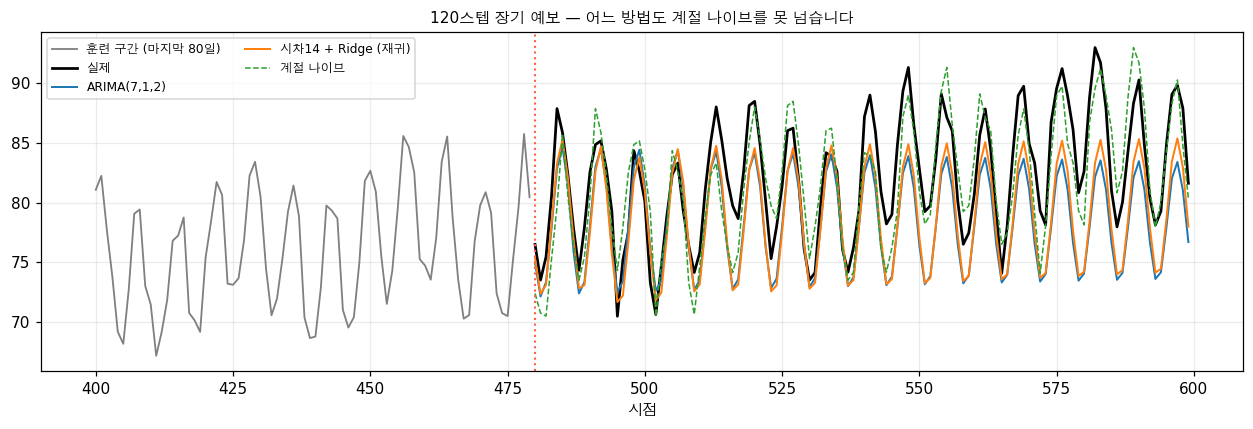


=> ⚠️ 120스텝을 한 번에 예보하면 학습한 모델이 전부 계절 나이브에 집니다.
   📗 원문이 'ARIMA 는 단변량 단기 예측에 좋다' 고 한 이유입니다.
   '단기' 라는 조건이 핵심입니다. 7절의 walk-forward 로 1스텝씩 재면 10절에서 본 것처럼 모델이 이깁니다.

   💡 지평선이 길어지면 왜 무너지나요?
      · ARIMA: 차분 모델이라 먼 미래로 가면 예보가 '평균 + 추세'로 수렴합니다
      · 재귀 Ridge: 예측을 다시 입력으로 쓰니 오차가 복리로 쌓입니다 (15절에서 측정)
      · 계절 나이브: '지난주 같은 요일'은 지평선이 길어도 품질이 안 떨어집니다

   📝 그래서 예측 과제를 받으면 지평선을 먼저 물어보세요.
      '다음 1일'과 '다음 120일'은 완전히 다른 문제입니다.


In [22]:
from statsmodels.tsa.arima.model import ARIMA

훈련끝A = 480
훈련A, 테스트A = 계열[:훈련끝A], 계열[훈련끝A:]
print(f"훈련 {len(훈련A)}개로 학습해서 {len(테스트A)}스텝을 한 번에 예보합니다")
print(f"(실무에서 흔한 '다음 분기 전체를 예측하라'와 같은 상황입니다)\n")

print(f"{'모델':<22}{'MAE':>9}{'RMSE':>9}{'학습(초)':>11}  비고")
print("-" * 68)
import time
ARIMA결과 = []
for 라벨, 차수 in [("ARIMA(7,1,2)", (7, 1, 2)), ("ARIMA(2,1,0) = AR(2)+차분", (2, 1, 0)),
                 ("ARIMA(0,1,2) = MA(2)+차분", (0, 1, 2))]:
    t0 = time.time()
    적합 = ARIMA(훈련A, order=차수).fit()
    경과 = time.time() - t0
    예보 = 적합.forecast(steps=len(테스트A))
    mae = np.mean(np.abs(테스트A - 예보))
    rmse = np.sqrt(np.mean((테스트A - 예보)**2))
    ARIMA결과.append((라벨, mae, 예보))
    print(f"{라벨:<22}{mae:>9.3f}{rmse:>9.3f}{경과:>11.2f}  AIC {적합.aic:.1f}")

# 같은 조건으로 시차+Ridge 를 재귀 예측시킵니다
X컷 = 훈련끝A - 14
리지 = Ridge(alpha=1.0).fit(X[:X컷], y[:X컷])
창 = list(계열[훈련끝A-14:훈련끝A])          # [t-14 ... t-1] 시간 순
재귀예측 = []
for _ in range(len(테스트A)):
    최근 = np.array(창[-14:][::-1])          # [t-1, t-2, ...] 로 뒤집습니다
    다음 = 리지.predict(최근.reshape(1, -1))[0]
    재귀예측.append(다음); 창.append(다음)
재귀예측 = np.array(재귀예측)
print(f"{'시차14 + Ridge (재귀)':<22}{np.mean(np.abs(테스트A-재귀예측)):>9.3f}"
      f"{np.sqrt(np.mean((테스트A-재귀예측)**2)):>9.3f}{'<0.01':>11}  한 번 학습, 재귀 예측")
기준계절A = 계열[훈련끝A-7:len(계열)-7]
print(f"{'계절 나이브(7일)':<22}{np.mean(np.abs(테스트A-기준계절A)):>9.3f}"
      f"{np.sqrt(np.mean((테스트A-기준계절A)**2)):>9.3f}{'0.00':>11}  학습 없음")

plt.figure(figsize=(11.5, 4))
plt.plot(np.arange(훈련끝A-80, 훈련끝A), 계열[훈련끝A-80:훈련끝A],
         lw=1.2, color="gray", label="훈련 구간 (마지막 80일)")
plt.plot(np.arange(훈련끝A, len(계열)), 테스트A, lw=1.8, color="black", label="실제")
for 라벨, _, 예보 in ARIMA결과[:1]:
    plt.plot(np.arange(훈련끝A, len(계열)), 예보, lw=1.3, label=라벨)
plt.plot(np.arange(훈련끝A, len(계열)), 재귀예측, lw=1.3, label="시차14 + Ridge (재귀)")
plt.plot(np.arange(훈련끝A, len(계열)), 기준계절A, lw=1.0, ls="--", label="계절 나이브")
plt.axvline(훈련끝A, color="tomato", ls=":", lw=1.4)
plt.title(f"{len(테스트A)}스텝 장기 예보 — 어느 방법도 계절 나이브를 못 넘습니다", fontsize=10)
plt.xlabel("시점"); plt.legend(fontsize=8, ncol=2); plt.grid(alpha=0.25)
plt.tight_layout(); plt.show()

print(f"\n=> ⚠️ {len(테스트A)}스텝을 한 번에 예보하면 학습한 모델이 전부 계절 나이브에 집니다.")
print(f"   📗 원문이 'ARIMA 는 단변량 단기 예측에 좋다' 고 한 이유입니다.")
print(f"   '단기' 라는 조건이 핵심입니다. 7절의 walk-forward 로 1스텝씩 재면 "
      f"10절에서 본 것처럼 모델이 이깁니다.")
print(f"\n   💡 지평선이 길어지면 왜 무너지나요?")
print(f"      · ARIMA: 차분 모델이라 먼 미래로 가면 예보가 '평균 + 추세'로 수렴합니다")
print(f"      · 재귀 Ridge: 예측을 다시 입력으로 쓰니 오차가 복리로 쌓입니다 (15절에서 측정)")
print(f"      · 계절 나이브: '지난주 같은 요일'은 지평선이 길어도 품질이 안 떨어집니다")
print(f"\n   📝 그래서 예측 과제를 받으면 지평선을 먼저 물어보세요.")
print(f"      '다음 1일'과 '다음 120일'은 완전히 다른 문제입니다.")

---

## 15. 다중 스텝 예측: 재귀 vs 직접

> 🔗 **앞 절과 이어서** — 14절에서 "지평선이 길어지면 무너진다"를 봤습니다.
> 그럼 길게 예측해야 할 때 어떻게 하나요? 전략이 세 가지입니다. 📗 연습문제 5번입니다.

> 📗 **원문** — "Forecasting Horizons and Strategies"

| 전략 | 방법 | 📗 원문의 평가 |
| --- | --- | --- |
| **재귀** (recursive) | 한 걸음 예측 → 그 예측을 입력으로 다시 한 걸음 | 간단하지만 **오차가 쌓입니다** |
| **직접** (direct) | 지평선마다 별도 모델 (t+1용, t+5용) | 오차가 안 쌓이지만 모델마다 샘플이 적습니다 |
| **다중 출력** (multi-output) | 한 모델이 모든 지평선을 동시에 출력 | 정보를 공유하지만 지원 모델이 제한적 |

> 📗 원문의 권고: "start with recursive for short horizons (1-5 steps)
> and direct for longer horizons."

이 권고가 맞는지 지평선을 1부터 30까지 늘려 가며 재 보겠습니다.

    지평선      재귀 MAE      직접 MAE         차이  승자
--------------------------------------------------------
      1       1.198       1.198     +0.000  같음
      3       1.465       1.447     +0.018  같음
      5       1.534       1.539     -0.005  같음
     10       1.993       1.663     +0.330  직접
     20       1.968       0.994     +0.974  직접
     30       1.855       1.036     +0.820  직접


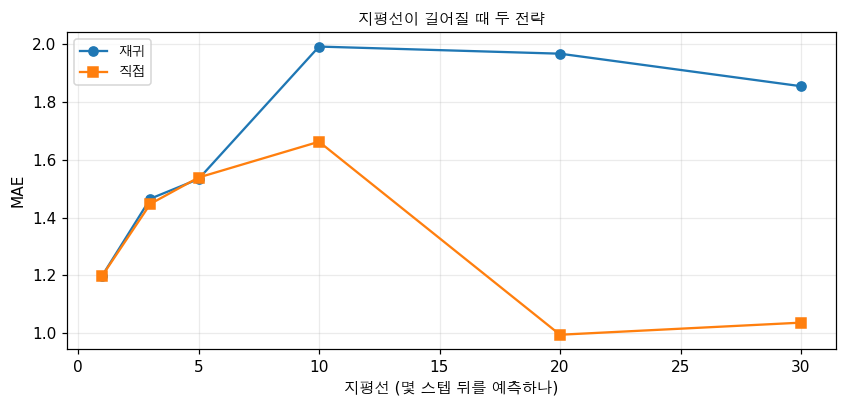


=> 📗 원문의 권고가 측정으로 확인됩니다.

   · 지평선 1~5: 두 전략 차이가 최대 0.018 입니다. 사실상 같습니다
     => 간단한 재귀를 쓰세요. 모델 하나만 관리하면 됩니다
   · 지평선 10 이상: 직접이 최대 0.974 앞섭니다
     => 지평선별 모델을 따로 만드는 비용을 낼 만합니다

   💡 재귀가 왜 길어지면 지나요?
      2스텝째부터 입력이 '실제 값'이 아니라 '내 예측'입니다.
      1스텝 오차가 2스텝 입력의 오차가 되고, 그게 3스텝으로 전파됩니다.
      📗 원문: 'each prediction uses the previous prediction, so mistakes compound.'

   ⚠️ 그런데 재귀 MAE 가 지평선 20 이후에 더 이상 안 커집니다. (1.968 -> 1.855)
      무한히 쌓이는 게 아니라 '계열의 평균 쪽으로 수렴'해서 거기서 멈춥니다.
      즉 아주 먼 미래에는 재귀 예측이 사실상 '평균 예측'이 됩니다.
      14절에서 ARIMA 장기 예보가 평평해진 것과 같은 현상입니다.


In [23]:
def 재귀예측하기(모델, Xf, 시작, 지평선, 시차수=14):
    # 각 시점에서 지평선만큼 재귀로 예측해 마지막 값만 모읍니다
    예측들 = []
    for i in range(시작, len(Xf) - 지평선):
        창 = list(Xf[i][::-1])                  # [t-14 ... t-1] 시간 순
        for _ in range(지평선):
            최근 = np.array(창[-시차수:][::-1])
            창.append(모델.predict(최근.reshape(1, -1))[0])
        예측들.append(창[-1])
    return np.array(예측들)


print(f"{'지평선':>7}{'재귀 MAE':>12}{'직접 MAE':>12}{'차이':>11}  승자")
print("-" * 56)
지평선기록 = []
기본모델 = Ridge(alpha=1.0).fit(X[:컷], y[:컷])
for H in (1, 3, 5, 10, 20, 30):
    # 재귀: 1스텝 모델 하나로 H번 굴립니다
    재귀 = 재귀예측하기(기본모델, X, 컷, H)
    재귀MAE = np.mean(np.abs(재귀 - y[컷+H-1:len(X)-1]))
    # 직접: 목표를 H-1 칸 앞으로 당겨 별도 모델을 학습합니다
    직접모델 = Ridge(alpha=1.0).fit(X[:컷-H], y[H-1:컷-1])
    직접 = 직접모델.predict(X[컷:len(X)-H])
    직접MAE = np.mean(np.abs(직접 - y[컷+H-1:len(X)-1]))
    지평선기록.append((H, 재귀MAE, 직접MAE))
    승자 = "같음" if abs(재귀MAE-직접MAE) < 0.02 else ("재귀" if 재귀MAE < 직접MAE else "직접")
    print(f"{H:>7}{재귀MAE:>12.3f}{직접MAE:>12.3f}{재귀MAE-직접MAE:>+11.3f}  {승자}")

plt.figure(figsize=(7.8, 3.8))
plt.plot([r[0] for r in 지평선기록], [r[1] for r in 지평선기록], "o-", label="재귀")
plt.plot([r[0] for r in 지평선기록], [r[2] for r in 지평선기록], "s-", label="직접")
plt.xlabel("지평선 (몇 스텝 뒤를 예측하나)"); plt.ylabel("MAE")
plt.title("지평선이 길어질 때 두 전략", fontsize=10)
plt.legend(fontsize=9); plt.grid(alpha=0.25)
plt.tight_layout(); plt.show()

짧은구간 = [r for r in 지평선기록 if r[0] <= 5]
긴구간 = [r for r in 지평선기록 if r[0] >= 10]
print(f"\n=> 📗 원문의 권고가 측정으로 확인됩니다.")
print(f"\n   · 지평선 1~5: 두 전략 차이가 최대 {max(abs(r[1]-r[2]) for r in 짧은구간):.3f} 입니다. "
      f"사실상 같습니다")
print(f"     => 간단한 재귀를 쓰세요. 모델 하나만 관리하면 됩니다")
print(f"   · 지평선 10 이상: 직접이 최대 {max(r[1]-r[2] for r in 긴구간):.3f} 앞섭니다")
print(f"     => 지평선별 모델을 따로 만드는 비용을 낼 만합니다")
print(f"\n   💡 재귀가 왜 길어지면 지나요?")
print(f"      2스텝째부터 입력이 '실제 값'이 아니라 '내 예측'입니다.")
print(f"      1스텝 오차가 2스텝 입력의 오차가 되고, 그게 3스텝으로 전파됩니다.")
print(f"      📗 원문: 'each prediction uses the previous prediction, so mistakes compound.'")
print(f"\n   ⚠️ 그런데 재귀 MAE 가 지평선 20 이후에 더 이상 안 커집니다. "
      f"({지평선기록[-2][1]:.3f} -> {지평선기록[-1][1]:.3f})")
print(f"      무한히 쌓이는 게 아니라 '계열의 평균 쪽으로 수렴'해서 거기서 멈춥니다.")
print(f"      즉 아주 먼 미래에는 재귀 예측이 사실상 '평균 예측'이 됩니다.")
print(f"      14절에서 ARIMA 장기 예보가 평평해진 것과 같은 현상입니다.")

In [24]:
# ✨ 추가 — 체제 변화가 있을 때 확장 창 vs 이동 창 (7절의 미결 질문)
변화계열 = 계열.copy()
변화계열[400:] += 25                 # 400 시점에 수준이 갑자기 점프합니다

X변, y변 = 시차특징만들기(변화계열, 14)
print("400 시점에 수준이 +25 점프하는 계열을 만들었습니다 (제품 가격 개편, 정책 변경 같은 상황)\n")
print(f"{'훈련 창':<22}{'MAE':>9}{'평균 훈련 개수':>15}")
print("-" * 48)
창기록 = []
for 라벨, 창크기 in [("확장 창 (전부 사용)", None), ("이동 창 (최근 300개)", 300),
                  ("이동 창 (최근 150개)", 150), ("이동 창 (최근 50개)", 50)]:
    오차, 개수 = [], []
    for 시작 in range(400, len(X변)-10, 10):
        구간 = (slice(0, 시작) if 창크기 is None
               else slice(max(0, 시작-창크기), 시작))
        m = Ridge(alpha=1.0).fit(X변[구간], y변[구간])
        오차.append(np.mean(np.abs(m.predict(X변[시작:시작+10]) - y변[시작:시작+10])))
        개수.append(구간.stop - (구간.start or 0))
    창기록.append((라벨, np.mean(오차), np.mean(개수)))
    print(f"{라벨:<21}{np.mean(오차):>9.3f}{np.mean(개수):>15.0f}")

최고창 = min(창기록, key=lambda r: r[1])
print(f"\n=> ⚠️ 📗 원문은 '세상이 바뀌면 이동 창을 쓰라' 고 합니다.")
print(f"   측정 결과 이 데이터에서는 '{최고창[0]}' 이 가장 좋습니다 (MAE {최고창[1]:.3f}).")
if 최고창[0].startswith("확장"):
    print(f"\n   체제 변화를 일부러 넣었는데도 확장 창이 이깁니다. 왜일까요?")
    print(f"   · 점프는 수준(level)만 바꿨고, 주기와 관성 구조는 그대로입니다")
    print(f"   · 시차 특징은 '절대 수준'이 아니라 '최근 값들과의 관계'를 씁니다.")
    print(f"     그래서 수준이 통째로 올라가도 모델이 거의 그대로 작동합니다")
    print(f"   · 반면 창을 좁히면 학습 샘플이 줄어 분산이 커집니다 (10단원)")
    print(f"\n   💡 정리하면 이동 창은 '구조가 바뀔 때' 쓰는 겁니다.")
    print(f"      수준만 바뀌는 변화는 차분이나 시차 특징이 이미 흡수합니다.")
    print(f"      '세상이 바뀌었다'를 '이동 창' 으로 바로 번역하지 말고,")
    print(f"      무엇이 바뀌었는지(수준인가 구조인가) 먼저 보세요.")

400 시점에 수준이 +25 점프하는 계열을 만들었습니다 (제품 가격 개편, 정책 변경 같은 상황)

훈련 창                        MAE       평균 훈련 개수
------------------------------------------------
확장 창 (전부 사용)             1.283            485
이동 창 (최근 300개)           1.325            300
이동 창 (최근 150개)           1.495            150
이동 창 (최근 50개)            2.000             50

=> ⚠️ 📗 원문은 '세상이 바뀌면 이동 창을 쓰라' 고 합니다.
   측정 결과 이 데이터에서는 '확장 창 (전부 사용)' 이 가장 좋습니다 (MAE 1.283).

   체제 변화를 일부러 넣었는데도 확장 창이 이깁니다. 왜일까요?
   · 점프는 수준(level)만 바꿨고, 주기와 관성 구조는 그대로입니다
   · 시차 특징은 '절대 수준'이 아니라 '최근 값들과의 관계'를 씁니다.
     그래서 수준이 통째로 올라가도 모델이 거의 그대로 작동합니다
   · 반면 창을 좁히면 학습 샘플이 줄어 분산이 커집니다 (10단원)

   💡 정리하면 이동 창은 '구조가 바뀔 때' 쓰는 겁니다.
      수준만 바뀌는 변화는 차분이나 시차 특징이 이미 흡수합니다.
      '세상이 바뀌었다'를 '이동 창' 으로 바로 번역하지 말고,
      무엇이 바뀌었는지(수준인가 구조인가) 먼저 보세요.


---

## 16. 정리

> 📗 **원문** — "Common Mistakes in Time Series" + Ship It / "Practical Tips"

### 📗 흔한 실수 표 (원문) + 이 노트북에서 확인한 곳

| 실수 | 왜 생기나 | 고치는 법 | 이 노트북 |
| --- | --- | --- | --- |
| 랜덤 분할 | 보통 ML 습관 | walk-forward 또는 시간순 분할 | 7·8절 |
| 미래 특징 사용 | 시점 t 값이 실수로 들어감 | 모든 특징의 시간 정렬을 감사 | 6절 |
| 계절성 과적합 | 달력 무늬를 외움 | 테스트에 주기 한 바퀴를 온전히 남김 | 10절 |
| 척도 변화 무시 | 매출이 두 배 돼도 무늬는 그대로 | 절대값 말고 변화율을 모델링 | 3·9절 |
| 시차 특징 과다 | "역사가 많으면 좋다" | ACF로 필요한 시차를 정함 | 4·13절 |
| 차분 안 하기 | "모델이 알아서 하겠지" | ⚠️ 아래 정정 참고 | 9절 |

### ⚠️ 이 노트북에서 원문과 달랐던 것 네 가지

> 전부 측정 결과입니다. 셀을 다시 돌려 확인하실 수 있습니다.

| 📗 원문의 주장 | 측정 결과 | 절 |
| --- | --- | --- |
| "트리는 추세를 다루고, 선형은 정상성이 필요하다" | **반대입니다.** 트리는 외삽을 못 해 차분이 필수고, Ridge는 차분 없이도 됩니다 | 9 |
| "시차 특징 + 부스팅이 가장 강한 출발점" | 차분을 건너뛰면 Ridge에 크게 집니다. 조건이 붙습니다 | 9 |
| "롤링 통계는 시차만으로 못 잡는 정보를 준다" | 롤링 평균은 시차들의 **정확한 선형 결합**입니다. 정보량 0 | 12 |
| "랜덤 CV 95% → 제대로 하면 55%" | 방향은 맞지만 크기가 모델마다 다릅니다 (Ridge는 거의 차이 없음) | 8 |

반대로 **측정으로 확인된** 원문의 주장들입니다.

| 📗 원문의 주장 | 결과 | 절 |
| --- | --- | --- |
| 목표 정렬 실수가 가장 흔한 버그 | ✅ R² 0.99999 가 나옵니다. 오류 없이 조용히 틀립니다 | 6 |
| 계절 나이브는 넘기 어렵다 | ✅ 차분 안 한 트리 모델들이 집니다 | 10 |
| MAPE는 실제값이 0이면 정의되지 않는다 | ✅ `inf` 가 나옵니다 | 11 |
| 1~5스텝은 재귀, 그보다 길면 직접 | ✅ 지평선 10부터 직접이 앞섭니다 | 15 |
| ACF의 뾰족한 지점이 계절 주기 | ✅ 시차 7, 14에서 솟았습니다 | 4 |
| 시차를 늘리면 과적합 위험이 커진다 | ✅ 편향-분산 곡선이 그대로 나옵니다 | 13 |

### 📗 실무 팁 (원문 "Practical Tips" 요약)

1. 먼저 그려 보세요. 30초 눈으로 보는 게 한 시간 자동 분석보다 많이 알려줍니다
2. **차분 먼저, 모델 나중.** 추세가 뚜렷하면 시차 특징 만들기 전에 차분하세요
3. 주기 한 바퀴는 테스트에 남기세요. 주간 계절성이면 최소 7일
4. 운영 중 감시하세요. 시계열 모델은 세상이 바뀌면서 낡습니다. 오차가 커지면 재학습
5. 체제 변화를 조심하세요. 코로나 이전 데이터로 이후를 예측할 수 없습니다
6. 치우친 계열은 로그를 취하세요. 매출·가격·횟수는 보통 오른쪽으로 치우쳐 있습니다

---

## 🚀 Ship It — `prompt-time-series-advisor.md`

> 📗 **원문** — 저장소의 `15-time-series/outputs/prompt-time-series-advisor.md` 에
> 실제 프롬프트가 들어 있습니다. 먼저 그 내용을 우리말로 옮기고, 그다음에
> ✨ 이 노트북의 측정 결과를 덧붙인 제 확장판을 둡니다.

### 📗 원문 프롬프트의 구조 (5단계)

> 📗 원문 첫 줄: "You are an expert in time series analysis and forecasting.
> When someone describes a prediction problem involving temporal data,
> help them frame it correctly and choose the right approach."

| 단계 | 원문이 묻는 것 |
| --- | --- |
| **1단계 — 문제 파악** | 목표가 수치인가 범주인가 · 예측 지평선 · 계열이 몇 개인가 · 외부 특징이 있나 · 주기(분/시/일/주/월) · 역사가 얼마나 긴가 |
| **2단계 — 함정 점검** | 랜덤 분할 금지 · 미래 특징 금지 · 정상성 확인 · ACF로 계절성 확인 · 목표의 척도(MAPE vs MAE) |
| **3단계 — 접근법 추천** | 아래 표 |
| **4단계 — 특징 체크리스트** | 시차값(ACF로 k 결정) · 롤링 통계 · 차분값 · 달력 특징 · 누적 특징 · 외부 특징 |
| **5단계 — 평가 규약** | walk-forward 필수 · MAE·MAPE·RMSE 보고 · 기준선 비교 |

📗 원문 3단계의 추천 표입니다.

| 상황 | 원문의 추천 |
| --- | --- |
| 단변량, 짧은 역사 | 지수평활 또는 ARIMA |
| 단변량, 계절성이 강함 | SARIMA 또는 Prophet |
| 외부 특징이 많음 | 시차 특징 + 그라디언트 부스팅 (XGBoost, LightGBM) |
| 관련 계열이 수백 개 | 계열 ID를 특징으로 넣은 LightGBM, 또는 전역 신경망 |
| 아주 긴 시퀀스, 복잡한 무늬 | LSTM 또는 Temporal Fusion Transformer |
| 빠른 기준선이 필요 | 계절 나이브 (10절) |

📗 원문 5단계의 '결과에서 의심할 신호' 세 가지도 그대로 옮깁니다.

| 📗 원문의 적신호 | 원문의 진단 | 이 노트북 |
| --- | --- | --- |
| 모델이 나이브 기준선보다 나쁘다 | 특징 누출 또는 잘못된 평가 | ⚠️ 10절에서 **세 번째 원인**을 찾았습니다. 트리의 외삽 불가입니다 |
| 랜덤 분할이 walk-forward보다 훨씬 좋다 | 미래 누출 | ✅ 8절에서 측정 (랜덤 포레스트 +0.56) |
| 지평선이 길어지면 성능이 급락한다 | 단기 자기상관에만 의존하는 모델 | ✅ 14·15절에서 측정 |

### ✨ 추가 — 측정 결과를 반영한 확장판

> ✨ 아래는 제가 쓴 것입니다. 📗 원문 5단계를 7단계로 늘리고,
> 이 노트북에서 반증된 항목(트리와 차분, 롤링 특징)을 질문으로 넣었습니다.

`outputs/prompt-time-series-advisor-ko.md` 처럼 별도 파일로 저장해 쓰세요.

```markdown
# 시계열 문제 진단 프롬프트

당신은 시계열 예측을 검토하는 선임 엔지니어입니다.
아래 순서대로 질문하고, 답을 다 듣기 전에는 모델을 추천하지 마세요.

## 1단계 — 문제 정의 (모델 이야기 전에)
- 예측 지평선이 몇 스텝입니까? (1스텝과 120스텝은 완전히 다른 문제입니다)
- 예측을 언제 쓰나요? 예측 시점에 어떤 정보까지 알 수 있습니까?
- 틀렸을 때 비용이 대칭입니까? (과소 예측이 더 비싸면 MAE 말고 비대칭 손실)

## 2단계 — 데이터 점검
- 계열을 그려 봤습니까? 추세·계절 주기·이상치·체제 변화를 눈으로 확인했습니까?
- 주기가 몇입니까? ACF로 확인했습니까?
- 결측이 있습니까? 결측을 어떻게 메웠습니까? (보간이 미래를 흘릴 수 있습니다)
- 실제값에 0이나 음수가 있습니까? (있으면 MAPE 금지)

## 3단계 — 누출 감사 (가장 중요)
- 모든 특징이 예측 시점에 **실제로 알 수 있는 값**입니까?
- 목표가 시점 t면 특징은 전부 t-1 이전입니까?
- 스케일러·결측 보간·타깃 인코딩을 전체 데이터에 먼저 적용했습니까? (그러면 누출입니다)
- 검증 R²가 0.99를 넘습니까? 그러면 누출을 먼저 의심하세요.

## 4단계 — 검증 설계
- 랜덤 분할이나 k-겹을 쓰고 있습니까? 쓰고 있으면 walk-forward로 바꾸세요.
- 테스트 구간에 계절 주기가 최소 한 바퀴 들어 있습니까?
- 확장 창입니까 이동 창입니까? 그 선택의 근거가 무엇입니까?
  (수준만 바뀌는 변화라면 확장 창이 보통 낫습니다)

## 5단계 — 기준선
- 다음 세 기준선의 점수를 적어 주세요. 모델 점수보다 먼저 필요합니다.
  1. 마지막 값 (어제와 같다)
  2. 계절 나이브 (지난 주기 같은 시점과 같다)
  3. 이동 평균 (최근 k개의 평균)
- 모델이 이 중 가장 센 것을 넘었습니까? 못 넘었으면 모델을 더 키우지 말고 원인을 찾으세요.

## 6단계 — 모델 선택
- 추세가 있고 트리 계열(랜덤 포레스트, 부스팅)을 쓸 계획입니까?
  => 반드시 차분하거나 추세를 제거하세요. 트리는 훈련 범위 밖을 예측할 수 없습니다.
- 외부 특징(날씨, 프로모션, 달력)이 많습니까? => 시차 특징 + 부스팅
- 단변량이고 지평선이 짧습니까? => ARIMA / 지수평활도 좋은 후보입니다
- 새 특징을 넣을 때마다 물어보세요. "이걸 기존 특징으로 계산할 수 있나?"
  계산할 수 있으면 보통 소용없습니다.

## 7단계 — 운영
- 예측 오차를 롤링으로 추적하고 있습니까?
- 재학습 주기와 '오차가 이만큼 커지면 재학습' 기준이 정해져 있습니까?
- 알려진 체제 변화(가격 개편, 정책 변경)를 특징으로 넣었습니까?

## 출력 형식
위 질문의 답을 받은 뒤에만 다음을 작성하세요.
1. 진단: 지금 설계에서 가장 위험한 지점 세 개
2. 기준선 표: 세 기준선 + 현재 모델
3. 다음 한 가지 행동: 가장 효과가 클 것 같은 변경 하나만
```

### 📗 또 하나의 산출물 — `code/time_series.py`

> 📗 **원문** — 저장소에 실제 파일이 있습니다 (352줄).
> 이 노트북은 그 중 핵심 구현을 **그대로 옮기고** 우리말 이름을 붙였습니다.

| 📗 원문의 이름 | 이 노트북의 이름 | 절 | 역할 |
| --- | --- | --- | --- |
| `make_lag_features` | `시차특징만들기` | 5 | 1D 계열 → 특징 행렬 + 목표 |
| `walk_forward_split` | `walk_forward분할` | 7 | 시간을 지키는 교차검증 분할기 |
| `SimpleAR` | `단순AR` | 13 | 시차 특징 위의 선형 회귀 |
| `check_stationarity` | `롤링통계` | 3 | 정상성 육안 검사 |
| `autocorrelation` | `자기상관` | 4 | ACF 계산 |
| `mae` / `mse` / `mape` | `세지표` | 11 | MAE / RMSE / MAPE |
| `difference` | `np.diff` 로 대체 | 3 | 차분 |
| `make_synthetic_series` / `make_seasonal_series` | 0절의 `계열` | 0 | 실습용 계열 생성 |
| (원문에 없음) | `차분복원평가` | 9 | ✨ 차분 학습 후 원래 척도로 되돌려 채점 |
| (원문에 없음) | `재귀예측하기` | 15 | ✨ 다중 스텝 재귀 예측 |
| (원문에 없음) | `특징만들기` | 12 | ✨ 롤링·달력 특징 조합 비교 |

> 📗 원문 파일에는 위 외에 `demo_*` 함수 일곱 개가 있습니다
> (`demo_stationarity`, `demo_autocorrelation`, `demo_lag_features`, `demo_walk_forward`,
> `demo_random_vs_walk_forward`, `demo_lag_comparison`, `demo_forecasting`).
> 이 노트북의 3·4·5·7·8·13·14절이 각각 그 역할을 합니다.

---

## 📚 용어 정리

> 📗 **원문** — "Key Terms" (설명은 쉬운 말로 다시 썼습니다)

| 용어 | 흔히 하는 말 | 실제 의미 |
| --- | --- | --- |
| **정상성** | "통계가 안 변한다" | 평균·분산·자기상관 구조가 시간에 따라 변하지 않는 계열 |
| **차분** | "연속한 값을 뺀다" | $y[t] - y[t-1]$ 을 계산해 추세를 없애고 정상성을 얻는 것 |
| **자기상관 (ACF)** | "자기와의 상관" | 계열과 그 계열을 k칸 밀어 놓은 사본의 상관. k의 함수로 봅니다 |
| **부분 자기상관 (PACF)** | "직접 상관만" | 더 짧은 시차들의 영향을 제거한 뒤 남은 시차 k의 자기상관 |
| **시차 특징** | "과거 값을 입력으로" | $y[t-1], y[t-2], \ldots, y[t-k]$ 를 특징으로 써서 $y[t]$ 를 맞추는 것 |
| **walk-forward 검증** | "시간을 지키는 교차검증" | 훈련 구간이 항상 테스트 구간보다 시간적으로 앞서는 평가 방식 |
| **ARIMA** | "고전 시계열 모델" | 과거 값(AR) + 차분(I) + 과거 오차(MA) 를 합친 모델 |
| **계절성** | "반복되는 달력 무늬" | 달력 주기(일·주·연)에 묶인 규칙적이고 예측 가능한 순환 |
| **추세** | "길게 본 방향" | 계열의 수준이 꾸준히 올라가거나 내려가는 성분 |
| **확장 창** | "역사 전부 쓰기" | 회차가 갈수록 훈련 집합이 커지는 walk-forward |
| **이동 창** | "최근 것만 쓰기" | 고정 길이 훈련 창이 앞으로 밀려가는 walk-forward |
| **과차분** | "너무 많이 뺐다" | 필요 이상으로 차분해서 분산만 키우고 신호를 깎은 상태 (3절) |
| **외삽** | "본 적 없는 범위를 예측" | 훈련 데이터의 값 범위를 벗어난 예측. 트리는 못 합니다 (9절) |

---

## 📖 더 읽을 것

> 📗 **원문** — "Further Reading"

- [Hyndman & Athanasopoulos, *Forecasting: Principles and Practice* (3판)](https://otexts.com/fpp3/), 무료로 공개된 시계열 교과서 중 최고
- [scikit-learn `TimeSeriesSplit`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html), 7절에서 쓴 walk-forward 분할기
- [statsmodels ARIMA 문서](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html), 14절의 진단 도구들
- [Makridakis et al., M5 경진대회 (2022)](https://www.sciencedirect.com/science/article/pii/S0169207021001874), ML 방법과 통계 방법을 대규모로 비교한 결과

---

## ✅ 이해 확인 퀴즈

> 📗 **원문** — 저장소의 `15-time-series/quiz.json` 에 5문항이 있습니다 (사전 2 + 사후 3).
> 먼저 그 문항을 우리말로 옮기고, 그다음에 ✨ 제가 만든 5문항을 둡니다.
>
> 📗 원문의 **연습문제**(Exercises)는 별개이고, 전부 본문에서 풀었습니다
> (1번→3절, 2번→아래 ✨ 퀴즈 뒤, 3번→8절, 4번→12절, 5번→15절).

### 📗 원문 퀴즈 (`quiz.json`)

[사전 1] 시계열에 랜덤 분할이 유효하지 않은 이유는?
1. 시계열은 아예 나눌 수 없다
2. 랜덤 분할은 분류 문제에만 통한다
3. 랜덤 분할은 미래 정보를 훈련 세트로 흘려서 모델이 반칙하게 만든다
4. 랜덤 분할은 데이터셋을 너무 작게 만든다

[사전 2] 시계열이 '정상'이라는 건 무슨 뜻인가?
1. 항상 위로 올라간다
2. 통계적 성질(평균·분산·자기상관)이 시간에 따라 변하지 않는다
3. 값이 시간이 지나도 전혀 안 변한다
4. 계절 무늬가 없다

[사후 1] 차분을 하는 목적은?
1. 값을 0~1 로 정규화하려고
2. 회귀를 분류로 바꾸려고
3. 데이터 점의 개수를 늘리려고
4. 추세를 없애고, 연속한 값의 변화를 모델링해 정상에 가깝게 만들려고

**[사후 2] $y[t]$ 를 예측할 때 '시차 3' 특징은 무엇인가?**
1. **3 스텝 전의 값: $y[t-3]$**
2. 현재 값과 3 스텝 뒤 값의 차이
3. 계열의 3차 도함수
4. 다음 3개 값의 평균

[사후 3] walk-forward 검증이 시계열에서 k-겹 교차검증보다 나은 이유는?
1. 계산이 더 빠르다
2. k-겹은 수치 데이터에 쓸 수 없다
3. walk-forward 가 훈련에 더 많은 데이터를 쓴다
4. 시간 순서를 지켜 과거로만 학습하고 미래로 검증하므로 선행 편향(lookahead bias)이 없다

> 📗 원문 해설의 핵심 문장: "K-fold CV shuffles data, potentially training on future
> to predict past (temporal leakage)."
> 이 노트북 1절의 '섞으면 구조가 사라진다'와 8절의 측정이 같은 이야기입니다.

### ✨ 추가 — 제가 만든 5문항

> ✨ 원문 퀴즈는 정의를 묻습니다. 아래는 측정 결과를 묻습니다.
> 답을 생각한 뒤 다음 셀을 돌려 보세요.

1. 시계열에서 랜덤 분할이 틀린 이유로 가장 정확한 것은?
1. 데이터가 정규분포를 따르지 않기 때문
2. 테스트 샘플보다 **시간적으로 나중인** 데이터가 훈련에 들어가기 때문
3. 샘플 수가 부족하기 때문
4. 특징의 척도가 다르기 때문

2. 추세가 뚜렷한 계열에 그라디언트 부스팅을 쓸 때 반드시 해야 할 것은?
1. 특징을 표준화한다
2. 트리 깊이를 늘린다
3. **차분해서 추세를 없앤다**
4. 학습률을 낮춘다

3. 롤링 평균(7) 특징을 시차 1~14 특징에 추가했습니다. Ridge 성능은?
1. 크게 좋아진다
2. 조금 좋아진다
3. 거의 그대로이거나 조금 나빠진다
4. 예측이 불가능해진다

4. 검증 R²가 0.9999 로 나왔습니다. 가장 먼저 할 일은?
1. 배포한다
2. 특징에 시점 t 값이 섞였는지 확인한다
3. 모델을 더 복잡하게 만든다
4. 하이퍼파라미터를 더 튜닝한다

5. 20스텝 뒤를 예측해야 합니다. 어느 전략이 유리한가?
1. 재귀: 모델 하나로 20번 굴린다
2. 직접: 20스텝용 모델을 따로 학습한다
3. 둘이 똑같다
4. 지평선과 무관하다

In [25]:
문항들 = [
    ("랜덤 분할이 틀린 이유", 2,
     "i.i.d. 가정 중 '독립'이 깨져서입니다. 랜덤으로 섞으면 테스트 시점보다 나중의 "
     "데이터가 훈련에 들어가 미래가 샙니다. 정규분포나 샘플 수는 상관없습니다.",
     "1절 (순서가 전부) · 7절 (walk-forward) · 8절 (부풀림을 측정)"),
    ("추세 + 부스팅", 3,
     "트리는 잎에 담긴 훈련 샘플의 평균을 내놓으므로 훈련 범위 밖을 예측할 수 없습니다. "
     "추세가 있으면 테스트 값이 범위를 넘어가므로 차분이 필수입니다. "
     "⚠️ 원문 표의 '트리는 추세를 다룬다'와 반대입니다.",
     "9절 (측정으로 반증) · 3절 (차분)"),
    ("롤링 평균을 추가하면", 3,
     "롤링 평균(7) = (lag1+...+lag7)/7 이라 시차 특징들의 정확한 선형 결합입니다. "
     "Ridge 가 이미 만들 수 있는 값이므로 새 정보가 0이고, 열만 늘어 조금 나빠집니다.",
     "12절 (R²=1.0 으로 선형 결합임을 확인) · 8단원 (다중공선성)"),
    ("R² 0.9999", 2,
     "현실의 시계열은 그렇게 안 맞습니다. 목표 정렬 함정(시점 t 값이 특징에 섞임)이 "
     "가장 흔한 원인입니다. 계수나 특징 중요도를 찍어 보면 한 특징이 전부를 차지합니다.",
     "6절 (일부러 버그를 만들어 R² 가 1.0 이 되는 걸 재현)"),
    ("20스텝 예측 전략", 2,
     "재귀는 2스텝째부터 자기 예측을 입력으로 쓰므로 오차가 복리로 쌓입니다. "
     "측정 결과 지평선 10부터 직접이 앞섭니다. 1~5스텝에서는 둘이 사실상 같습니다.",
     "15절 (지평선 1~30 측정) · 14절 (장기 예보가 평평해지는 현상)"),
]

print("=" * 80)
for 번호, (제목, 정답, 해설, 어디) in enumerate(문항들, 1):
    print(f"{번호}. {제목}")
    print(f"   정답: {정답}번")
    print(f"   해설: {해설}")
    print(f"   이 노트북: {어디}")
    print("-" * 80)

print("\n💡 채점 기준")
print("   5개 다 맞음 -> Phase 2 완주입니다. 수고하셨습니다")
print("   3~4개 맞음  -> 틀린 문항의 '이 노트북' 절만 다시 읽으세요")
print("   2개 이하    -> 6절(누출)과 9절(외삽)을 먼저 다시 보세요.")
print("                 이 단원에서 가장 많이 틀리는 두 지점입니다")

1. 랜덤 분할이 틀린 이유
   정답: 2번
   해설: i.i.d. 가정 중 '독립'이 깨져서입니다. 랜덤으로 섞으면 테스트 시점보다 나중의 데이터가 훈련에 들어가 미래가 샙니다. 정규분포나 샘플 수는 상관없습니다.
   이 노트북: 1절 (순서가 전부) · 7절 (walk-forward) · 8절 (부풀림을 측정)
--------------------------------------------------------------------------------
2. 추세 + 부스팅
   정답: 3번
   해설: 트리는 잎에 담긴 훈련 샘플의 평균을 내놓으므로 훈련 범위 밖을 예측할 수 없습니다. 추세가 있으면 테스트 값이 범위를 넘어가므로 차분이 필수입니다. ⚠️ 원문 표의 '트리는 추세를 다룬다'와 반대입니다.
   이 노트북: 9절 (측정으로 반증) · 3절 (차분)
--------------------------------------------------------------------------------
3. 롤링 평균을 추가하면
   정답: 3번
   해설: 롤링 평균(7) = (lag1+...+lag7)/7 이라 시차 특징들의 정확한 선형 결합입니다. Ridge 가 이미 만들 수 있는 값이므로 새 정보가 0이고, 열만 늘어 조금 나빠집니다.
   이 노트북: 12절 (R²=1.0 으로 선형 결합임을 확인) · 8단원 (다중공선성)
--------------------------------------------------------------------------------
4. R² 0.9999
   정답: 2번
   해설: 현실의 시계열은 그렇게 안 맞습니다. 목표 정렬 함정(시점 t 값이 특징에 섞임)이 가장 흔한 원인입니다. 계수나 특징 중요도를 찍어 보면 한 특징이 전부를 차지합니다.
   이 노트북: 6절 (일부러 버그를 만들어 R² 가 1.0 이 되는 걸 재현)
-----------------------------------------

---

## 🎓 Phase 2 를 마치며

15단원까지 왔습니다. 돌아보면 이 Phase 의 뼈대는 이렇습니다.

| 묶음 | 단원 | 한 줄 요약 |
| --- | --- | --- |
| 모델 만들기 | 2~6 | 선형·로지스틱·트리·SVM·KNN 을 밑바닥부터 |
| 레이블 없이 | 7 | 군집과 차원 축소 |
| 데이터 다루기 | 8 | 특징을 만들고 고르는 법 |
| 정직하게 재기 | 9~10 | 평가 지표와 편향-분산 |
| 성능 올리기 | 11~12 | 앙상블과 하이퍼파라미터 탐색 |
| 운영에 올리기 | 13 | 파이프라인과 추적 |
| 특수한 데이터 | 14~15 | 텍스트(나이브 베이즈)와 시간(시계열) |

### 🔑 이 Phase 에서 반복해서 나온 교훈 세 가지

① 측정하지 않은 주장은 믿지 마세요.
이 노트북 묶음에서 원문의 주장이 측정과 달랐던 경우가 열 번을 넘습니다.
"표준화는 이상치에 강건하다", "TF-IDF가 횟수보다 낫다", "트리는 추세를 다룬다" 같은 것들이요.
전부 **조건부**로 맞거나 틀렸습니다. 직접 재 보면 그 조건이 보입니다.

② 기준선 없는 점수는 숫자일 뿐입니다.
정확도 88%가 좋은 건지 나쁜 건지, 기준선을 모르면 알 수 없습니다.
나이브 베이즈는 1초 기준선이고(14단원), 계절 나이브는 학습 없는 기준선입니다(15단원).

③ 가장 흔한 버그는 '조용히 좋은 점수'입니다.
누출은 오류를 내지 않습니다. 점수를 올립니다.
13단원의 스케일러 누출, 15단원의 목표 정렬 함정이 그 모습이었습니다.
점수가 기대보다 좋으면 먼저 의심하세요.